# All-dataset metrics: simplified boxplots

This notebook compares a dataset-specific Syndri fixed-removal condition with raw expression, SPLIT, ResolVI, ovrlpy, and CellAdmix where results are available. Change `SYNDRI_TARGET_FRACTIONS` in the configuration cell to select the precomputed fraction used for each dataset.

For aging brain MERFISH, Raw and SPLIT retain their regenerated RCTD/SPLIT metric sources; Syndri uses hard-zero metrics from the milestone 87 predictions. ResolVI uses its regenerated-interim metric run. CellAdmix currently has results for six NSCLC CosMx slices. Other datasets keep their existing result paths.

Every plotted observation represents one tissue slice. Metrics with multiple cell-type comparisons are averaged within a slice before boxplots are calculated, preventing slices with more annotated subtypes from receiving more weight.

Syndri separation, count, and T-cell metrics use **hard zeroing** from `results/metrics/syndri_zero_20261017_224620/unfiltered/`. The QC section uses the same run’s `qc10counts5genes/non_tcell/` results. Raw and competitor metrics retain their existing sources. Only completed hard-zero slice results are loaded; missing results never fall back to probability scaling.

Reference cosine similarity now covers **all annotated cell types in all four datasets**, using `REFERENCE_COSINE_RUN`. Only marker-contamination assessment remains T-cell-specific.


In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

# Path to where you saved the downloaded Arial file
font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
REPO = Path('/home/jwinchel/Syndri')
FIGURE_DIR = REPO / 'figures' / 'outputs'
ROOT = Path("/work/magroup/skrieger/Syndri/data/datasets")
REFERENCE_COSINE_RUN = 'all_cell_type_reference_cosine_20261018_163601'
SYNDRI_METRICS_RUN = "syndri_zero_20261017_224620"
AGINGBRAIN_METRICS = ROOT / "agingbrain_merfish" / "results" / "metrics"
METRIC_ROOT_OVERRIDES = {
    ("agingbrain_merfish", "non_tcell", None): (
        AGINGBRAIN_METRICS / "model_runs"
        / "10x_agingbrain_donors5to8_m87_regenerated_rctd_20261010" / "non_tcell"
    ),
    ("agingbrain_merfish", "non_tcell", "resolvi"): (
        AGINGBRAIN_METRICS / "competitors" / "resolvi_regenerated_interim_20261011"
        / "non_tcell"
    ),
}

DATASET_TITLES = {
    # "agingbrain_merfish": "Aging brain MERFISH",
    "brain_merfish": "Brain MERFISH",
    "nsclc_cosmx": "NSCLC CosMx",
    "breast_xenium": "Breast Xenium",
}
DATASET_ALIASES = {
    # "agingbrain_merfish": "AM",  # Aging Brain MERFISH
    "brain_merfish": "BM",       # Brain MERFISH
    "nsclc_cosmx": "NC",         # NSCLC CosMx
    "breast_xenium": "BX",       # Breast Xenium
}
TCELL_DATASETS = {
    "breast_xenium": "Breast Xenium",
    "nsclc_cosmx": "NSCLC CosMx",
}

# Select exactly one of the fixed-removal Syndri conditions.
SYNDRI_TARGET_FRACTIONS = {
    # "agingbrain_merfish": 0.50,
    "brain_merfish": 0.50,
    "nsclc_cosmx": 0.5,
    "breast_xenium": 0.50,
}
SYNDRI_LABEL = "Syndri"
OVRLPY_METHODS = {
    # "vsi_lt_0_5": "ovrlpy <0.5",
    "vsi_lt_0_7": "ovrlpy",
}
BASE_METHOD_ORDER = ["SPLIT", "ResolVI", *OVRLPY_METHODS.values(), SYNDRI_LABEL]
METHOD_ORDER = [*BASE_METHOD_ORDER[:-1], "CellAdmix", SYNDRI_LABEL]
ALTERNATIVE_METHODS = ["Raw", *METHOD_ORDER[:-1]]
COUNT_METHOD_ORDER = ["Raw", *METHOD_ORDER]
DELTA_PLOT_ORDER = METHOD_ORDER.copy()
hex = sns.color_palette("deep", n_colors=6).as_hex()
COLORS = {
    "Raw": hex[0],
    SYNDRI_LABEL: hex[1],
    "SPLIT": hex[2],
    "ResolVI": hex[3],
    "CellAdmix": hex[4],
    # OVRLPY_METHODS["vsi_lt_0_5"]: hex[4],
    OVRLPY_METHODS["vsi_lt_0_7"]: hex[5],
    # "Raw": "#8F8F8F",
    # SYNDRI_LABEL: "#2688BE",
    # "SPLIT": "#8260A8",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,

})

print(f"Selected Syndri method: {SYNDRI_LABEL} (hard zeroing; {SYNDRI_METRICS_RUN})")

Selected Syndri method: Syndri (hard zeroing; syndri_zero_20261017_224620)


In [10]:
def load_per_slice_csv(dataset, family, filename, usecols=None, competitor=None):
    """Load one result file per slice and attach dataset/slice provenance."""
    frames = []
    root = METRIC_ROOT_OVERRIDES.get((dataset, family, competitor))
    if root is None:
        root = ROOT / dataset / "results" / "metrics"
        if competitor is not None:
            root = root / "competitors" / competitor
        root = root / family
    for path in sorted(root.glob(f"*/{filename}")):
        if path.stat().st_size == 0:
            continue
        try:
            frame = pd.read_csv(path, usecols=usecols, low_memory=False)
        except pd.errors.EmptyDataError:
            continue
        frame["dataset"] = dataset
        frame["slice"] = path.parent.name
        frames.append(frame)
    result = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    if competitor is None:
        # Keep the existing Raw/SPLIT rows, replacing only Syndri conditions.
        condition_col = "case" if family == "non_tcell" else "condition"
        if not result.empty and condition_col in result:
            result = result.loc[~result[condition_col].astype(str).str.startswith(
                "cleaned_admixed_removed_frac_", na=False
            )].copy()
        zero_root = (ROOT / dataset / "results" / "metrics" / SYNDRI_METRICS_RUN
                     / "unfiltered" / family)
        zero_frames = []
        for path in sorted(zero_root.glob(f"*/{filename}")):
            if not (path.parent / "complete.json").is_file():
                continue
            try:
                frame = pd.read_csv(path, usecols=usecols, low_memory=False)
            except pd.errors.EmptyDataError:
                continue
            frame = frame.loc[frame[condition_col].astype(str).str.startswith(
                "cleaned_admixed_removed_frac_", na=False
            )].copy()
            if not frame.empty and not frame["cleaning_mode"].eq("zero").all():
                raise ValueError(f"Expected hard-zero Syndri metrics: {path}")
            frame["dataset"] = dataset
            frame["slice"] = path.parent.name
            zero_frames.append(frame)
        if not zero_frames:
            raise FileNotFoundError(f"No completed hard-zero Syndri metrics: {zero_root}")
        result = pd.concat([result, *zero_frames], ignore_index=True)
        print(f"{dataset}/{family}/{filename}: hard-zero Syndri slices = "
              f"{sum(frame['slice'].nunique() for frame in zero_frames)}")
    return result


def valid_rows(frame):
    result = frame.copy()
    if "error" in result:
        result = result.loc[result["error"].fillna("").astype(str).eq("")].copy()
    return result


def fixed_syndri_mask(frame, condition_col):
    fraction = pd.to_numeric(
        frame.get("target_removed_fraction"), errors="coerce"
    )
    target = frame["dataset"].map(SYNDRI_TARGET_FRACTIONS)

    return (
        frame[condition_col].astype(str).str.startswith(
            "cleaned_admixed_removed_frac_", na=False
        )
        & np.isclose(fraction, target, rtol=0, atol=1e-8)
    )


def boxplot_with_points(
    ax, data, x, y, order, palette, ylabel="", zero_line=False
):
    sns.boxplot(
        data=data, x=x, y=y, hue=x, order=order, hue_order=order,
        palette=palette, legend=False, width=0.58, showfliers=False,
        linewidth=1.1, ax=ax,
    )
    sns.stripplot(
        data=data, x=x, y=y, order=order, color="#222222",
        alpha=0.55, size=3.5, jitter=0.13, ax=ax,
    )
    if zero_line:
        ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.22)


def add_n_labels(ax, data, category_col, order):
    ymax = ax.get_ylim()[1]
    ymin = ax.get_ylim()[0]
    y = ymax - 0.04 * (ymax - ymin)
    for position, category in enumerate(order):
        n = data.loc[data[category_col].eq(category), "slice"].nunique()
        ax.text(position, y, f"n={n}", ha="center", va="top", fontsize=8)


## Non-T-cell clustering metrics

The first figure shows each metric on its original scale for Raw, SPLIT, ResolVI, both ovrlpy thresholds, and Syndri. The second uses paired slices and orients deltas so positive always means improvement over raw expression. Metrics are ordered by Syndri's mean percentage-point advantage over the best available alternative, averaging matched slices within each dataset and then averaging datasets equally. CH = Calinski–Harabasz; DB = Davies–Bouldin; NMI = Leiden NMI; ARI = Leiden ARI.


In [11]:
non_tcell_frames = []
for dataset in DATASET_TITLES:
    frame = load_per_slice_csv(dataset, "non_tcell", "non_tcell_metrics.csv")
    if not frame.empty:
        non_tcell_frames.append(frame)
    resolvi = load_per_slice_csv(
        dataset, "non_tcell", "non_tcell_metrics.csv", competitor="resolvi"
    )
    if not resolvi.empty:
        non_tcell_frames.append(resolvi)
    celladmix = load_per_slice_csv(
        dataset, "non_tcell", "non_tcell_metrics.csv", competitor="celladmix_k1p5ct"
    )
    if not celladmix.empty:
        non_tcell_frames.append(celladmix)
    for threshold in OVRLPY_METHODS:
        ovrlpy = load_per_slice_csv(
            dataset, "non_tcell", "non_tcell_metrics.csv",
            competitor=f"ovrlpy_pixel_correction/{threshold}",
        )
        if not ovrlpy.empty:
            non_tcell_frames.append(ovrlpy)

if not non_tcell_frames:
    raise FileNotFoundError("No non_tcell_metrics.csv files were found.")

non_tcell = valid_rows(pd.concat(non_tcell_frames, ignore_index=True))
non_tcell["target_removed_fraction"] = pd.to_numeric(
    non_tcell.get("target_removed_fraction"), errors="coerce"
)
non_tcell["method"] = np.select(
    [
        non_tcell["case"].eq("admixed"),
        fixed_syndri_mask(non_tcell, "case"),
        non_tcell["case"].eq("SPLIT"),
        non_tcell["case"].eq("ResolVI"),
        non_tcell["case"].eq("celladmix_k1p5ct"),
        # non_tcell["case"].eq("ovrlpy_vsi_lt_0_5"),
        non_tcell["case"].eq("ovrlpy_vsi_lt_0_7"),
    ],
    ["Raw", SYNDRI_LABEL, "SPLIT", "ResolVI", "CellAdmix", *OVRLPY_METHODS.values()],
    default="",
)
non_tcell = non_tcell.loc[non_tcell["method"].ne("")].copy()

NON_TCELL_METRICS = {
    "silhouette_score": ("Silhouette", 1),
    "calinski_harabasz": ("CH", 1),
    "davies_bouldin": ("DB", -1),
    "leiden_nmi_vs_label": ("NMI", 1),
    "leiden_adjusted_rand_vs_label": ("ARI", 1),
}

original_rows = []
for metric, (label, _) in NON_TCELL_METRICS.items():
    values = (
        non_tcell.groupby(["dataset", "slice", "method"], observed=True)[metric]
        .mean().rename("value").reset_index()
    )
    original_rows.append(values.assign(metric=label))
non_tcell_original = (
    pd.concat(original_rows, ignore_index=True).dropna(subset=["value"])
)

rows = []
percent_rows = []
for metric, (label, direction) in NON_TCELL_METRICS.items():
    values = non_tcell.pivot_table(
        index=["dataset", "slice"], columns="method", values=metric, aggfunc="mean"
    )
    if "Raw" not in values:
        continue
    for method in METHOD_ORDER:
        if method not in values:
            continue
        improvement = (values[method] - values["Raw"]) * direction
        rows.append(improvement.rename("improvement").reset_index().assign(
            method=method, metric=label
        ))
        raw = values["Raw"].replace(0, np.nan)
        percent_change = 100 * direction * (values[method] - raw) / raw
        percent_rows.append(
            percent_change.rename("percent_change").reset_index().assign(
                method=method, metric=label
            )
        )

non_tcell_plot = pd.concat(rows, ignore_index=True).dropna(subset=["improvement"])
non_tcell_percent = (
    pd.concat(percent_rows, ignore_index=True)
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["percent_change"])
)
# Rank metrics by Syndri's advantage over the best available alternative on matched slices.
# Average within dataset first so each dataset contributes equally.
paired_percent = non_tcell_percent.pivot_table(
    index=["dataset", "slice", "metric"], columns="method",
    values="percent_change", aggfunc="mean",
)
paired_percent = paired_percent.dropna(subset=["SPLIT", "ResolVI", SYNDRI_LABEL])
metric_advantage = (
    (paired_percent[SYNDRI_LABEL] - paired_percent[ALTERNATIVE_METHODS[1:]].max(axis=1))
    .groupby(level=["dataset", "metric"]).mean()
    .groupby(level="metric").mean()
)
metric_order = (
    metric_advantage.reindex([label for label, _ in NON_TCELL_METRICS.values()])
    .sort_values(ascending=False, kind="stable").index.tolist()
)
print(non_tcell_plot.groupby(["dataset", "method"])["slice"].nunique())


brain_merfish/non_tcell/non_tcell_metrics.csv: hard-zero Syndri slices = 3
nsclc_cosmx/non_tcell/non_tcell_metrics.csv: hard-zero Syndri slices = 8
breast_xenium/non_tcell/non_tcell_metrics.csv: hard-zero Syndri slices = 19
dataset        method   
brain_merfish  ResolVI       3
               SPLIT         3
               Syndri        3
breast_xenium  CellAdmix    18
               ResolVI      19
               SPLIT        19
               Syndri       19
               ovrlpy       19
nsclc_cosmx    CellAdmix     7
               ResolVI       8
               SPLIT         8
               Syndri        8
               ovrlpy        8
Name: slice, dtype: int64


/tmp/ipykernel_11778/1080563489.py:16: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_11778/1080563489.py:16: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_11778/1080563489.py:16: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


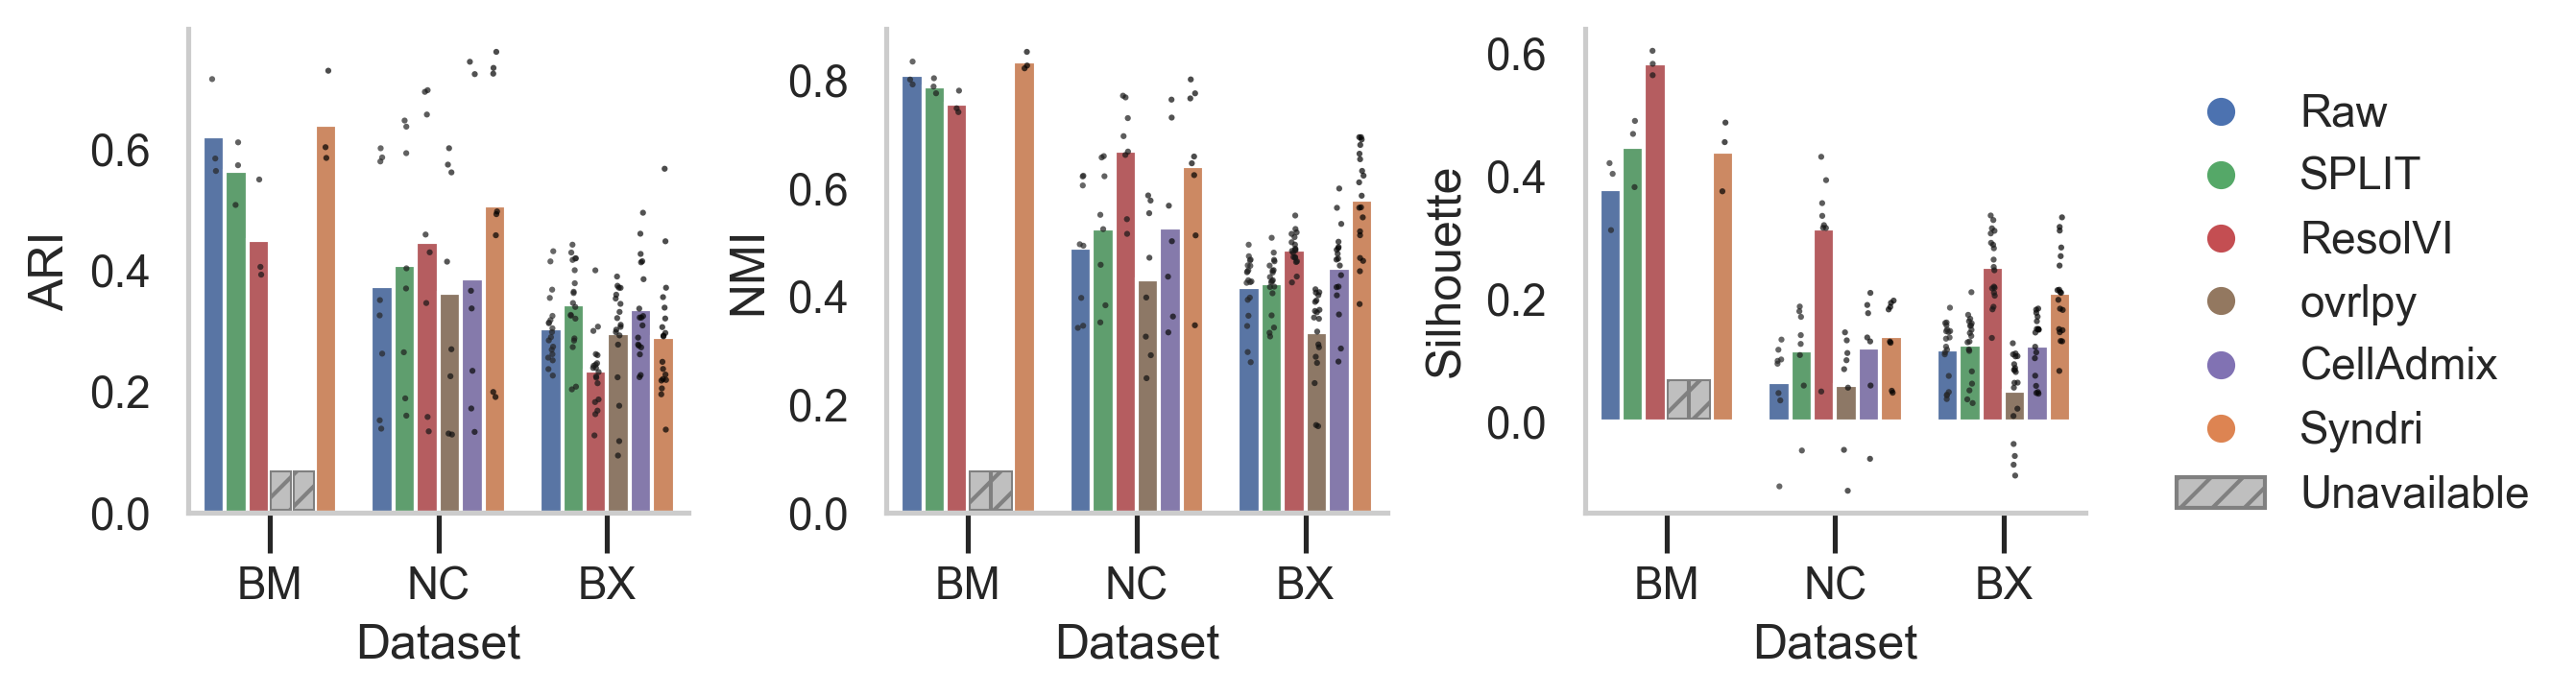

In [12]:
# One multi-panel swarm figure: metrics are panels and datasets are x groups.
swarm_data = non_tcell_original.copy()
swarm_data["dataset_alias"] = swarm_data["dataset"].map(DATASET_ALIASES)
dataset_order = list(DATASET_ALIASES.values())
# print(metric_order)
metric_order = ['ARI','NMI','Silhouette']
fig, axes = plt.subplots(1, 3, figsize=(7.5, 3), squeeze=False,dpi=300)
for ax, metric in zip(axes.flat, metric_order):
    subset = swarm_data.loc[swarm_data["metric"].eq(metric)]
    sns.barplot(
            data=subset, x="dataset_alias", y="value", hue="method",
            order=dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
            palette=COLORS, legend=False, ax=ax,errorbar=None
        )
    
    sns.stripplot(
        data=subset, x="dataset_alias", y="value", hue="method",
        order=dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        color='black', size=1.5, alpha=0.7, legend=False, ax=ax,jitter=True,
        # edgecolor='black',linewidth=1
    )

    # Mark dataset-method combinations with no observations. These short bars
    # indicate missing data; their height is not a metric value.
    present = set(zip(
        subset.loc[subset["value"].notna(), "dataset_alias"],
        subset.loc[subset["value"].notna(), "method"],
    ))
    ymin, ymax = ax.get_ylim()
    slot_width = 0.8 / len(COUNT_METHOD_ORDER)
    for dataset_index, dataset in enumerate(dataset_order):
        for method_index, method in enumerate(COUNT_METHOD_ORDER):
            if (dataset, method) in present:
                continue
            center = dataset_index - 0.4 + (method_index + 0.5) * slot_width
            ax.bar(
                center, 0.08 * (ymax - ymin), width=0.9 * slot_width,
                bottom=0.005, color="0.75", edgecolor="0.5",
                hatch="///", linewidth=0.5, zorder=2,
            )
    ax.set_ylim(ymin, ymax)

    # ax.set_title(metric, fontsize=11, pad=10)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(metric)
    ax.tick_params(
        axis="x", top=False, labeltop=False, bottom=True, labelbottom=True, size=10
    )
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)

for ax in axes.flat[len(metric_order):]:
    ax.remove()

legend_handles = [
    plt.Line2D(
        [0], [0], marker="o", linestyle="", markersize=6,
        markerfacecolor=COLORS[method], markeredgecolor=COLORS[method],
        label=method,
    )
    for method in COUNT_METHOD_ORDER
]
legend_handles.append(
    plt.Rectangle((0, 0), 1, 1, facecolor="0.75", edgecolor="0.5",
                  hatch="///", label="Unavailable")
)
fig.legend(
    handles=legend_handles, loc="lower center", ncol=1,
    bbox_to_anchor=(1.1, 0.31), frameon=False,
)
# fig.suptitle("Cell-type separation metrics", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout(rect=[0, 0.12, 1, 0.98], h_pad=1.0, w_pad=0.8)
fig.savefig(FIGURE_DIR / 'SuppFig2_sep.svg',bbox_inches='tight')
plt.show()

In [13]:
print(COLORS)

{'Raw': '#4c72b0', 'Syndri': '#dd8452', 'SPLIT': '#55a868', 'ResolVI': '#c44e52', 'CellAdmix': '#8172b3', 'ovrlpy': '#937860'}


### Cell-type separation: paired change from Raw

Each observation is one tissue slice with Raw and the available cleaned methods on the same slice. ovrlpy is evaluated only for NSCLC CosMx and breast Xenium. The dashed line marks the slice-level Raw baseline at zero; positive change indicates improvement (Davies–Bouldin is reversed).


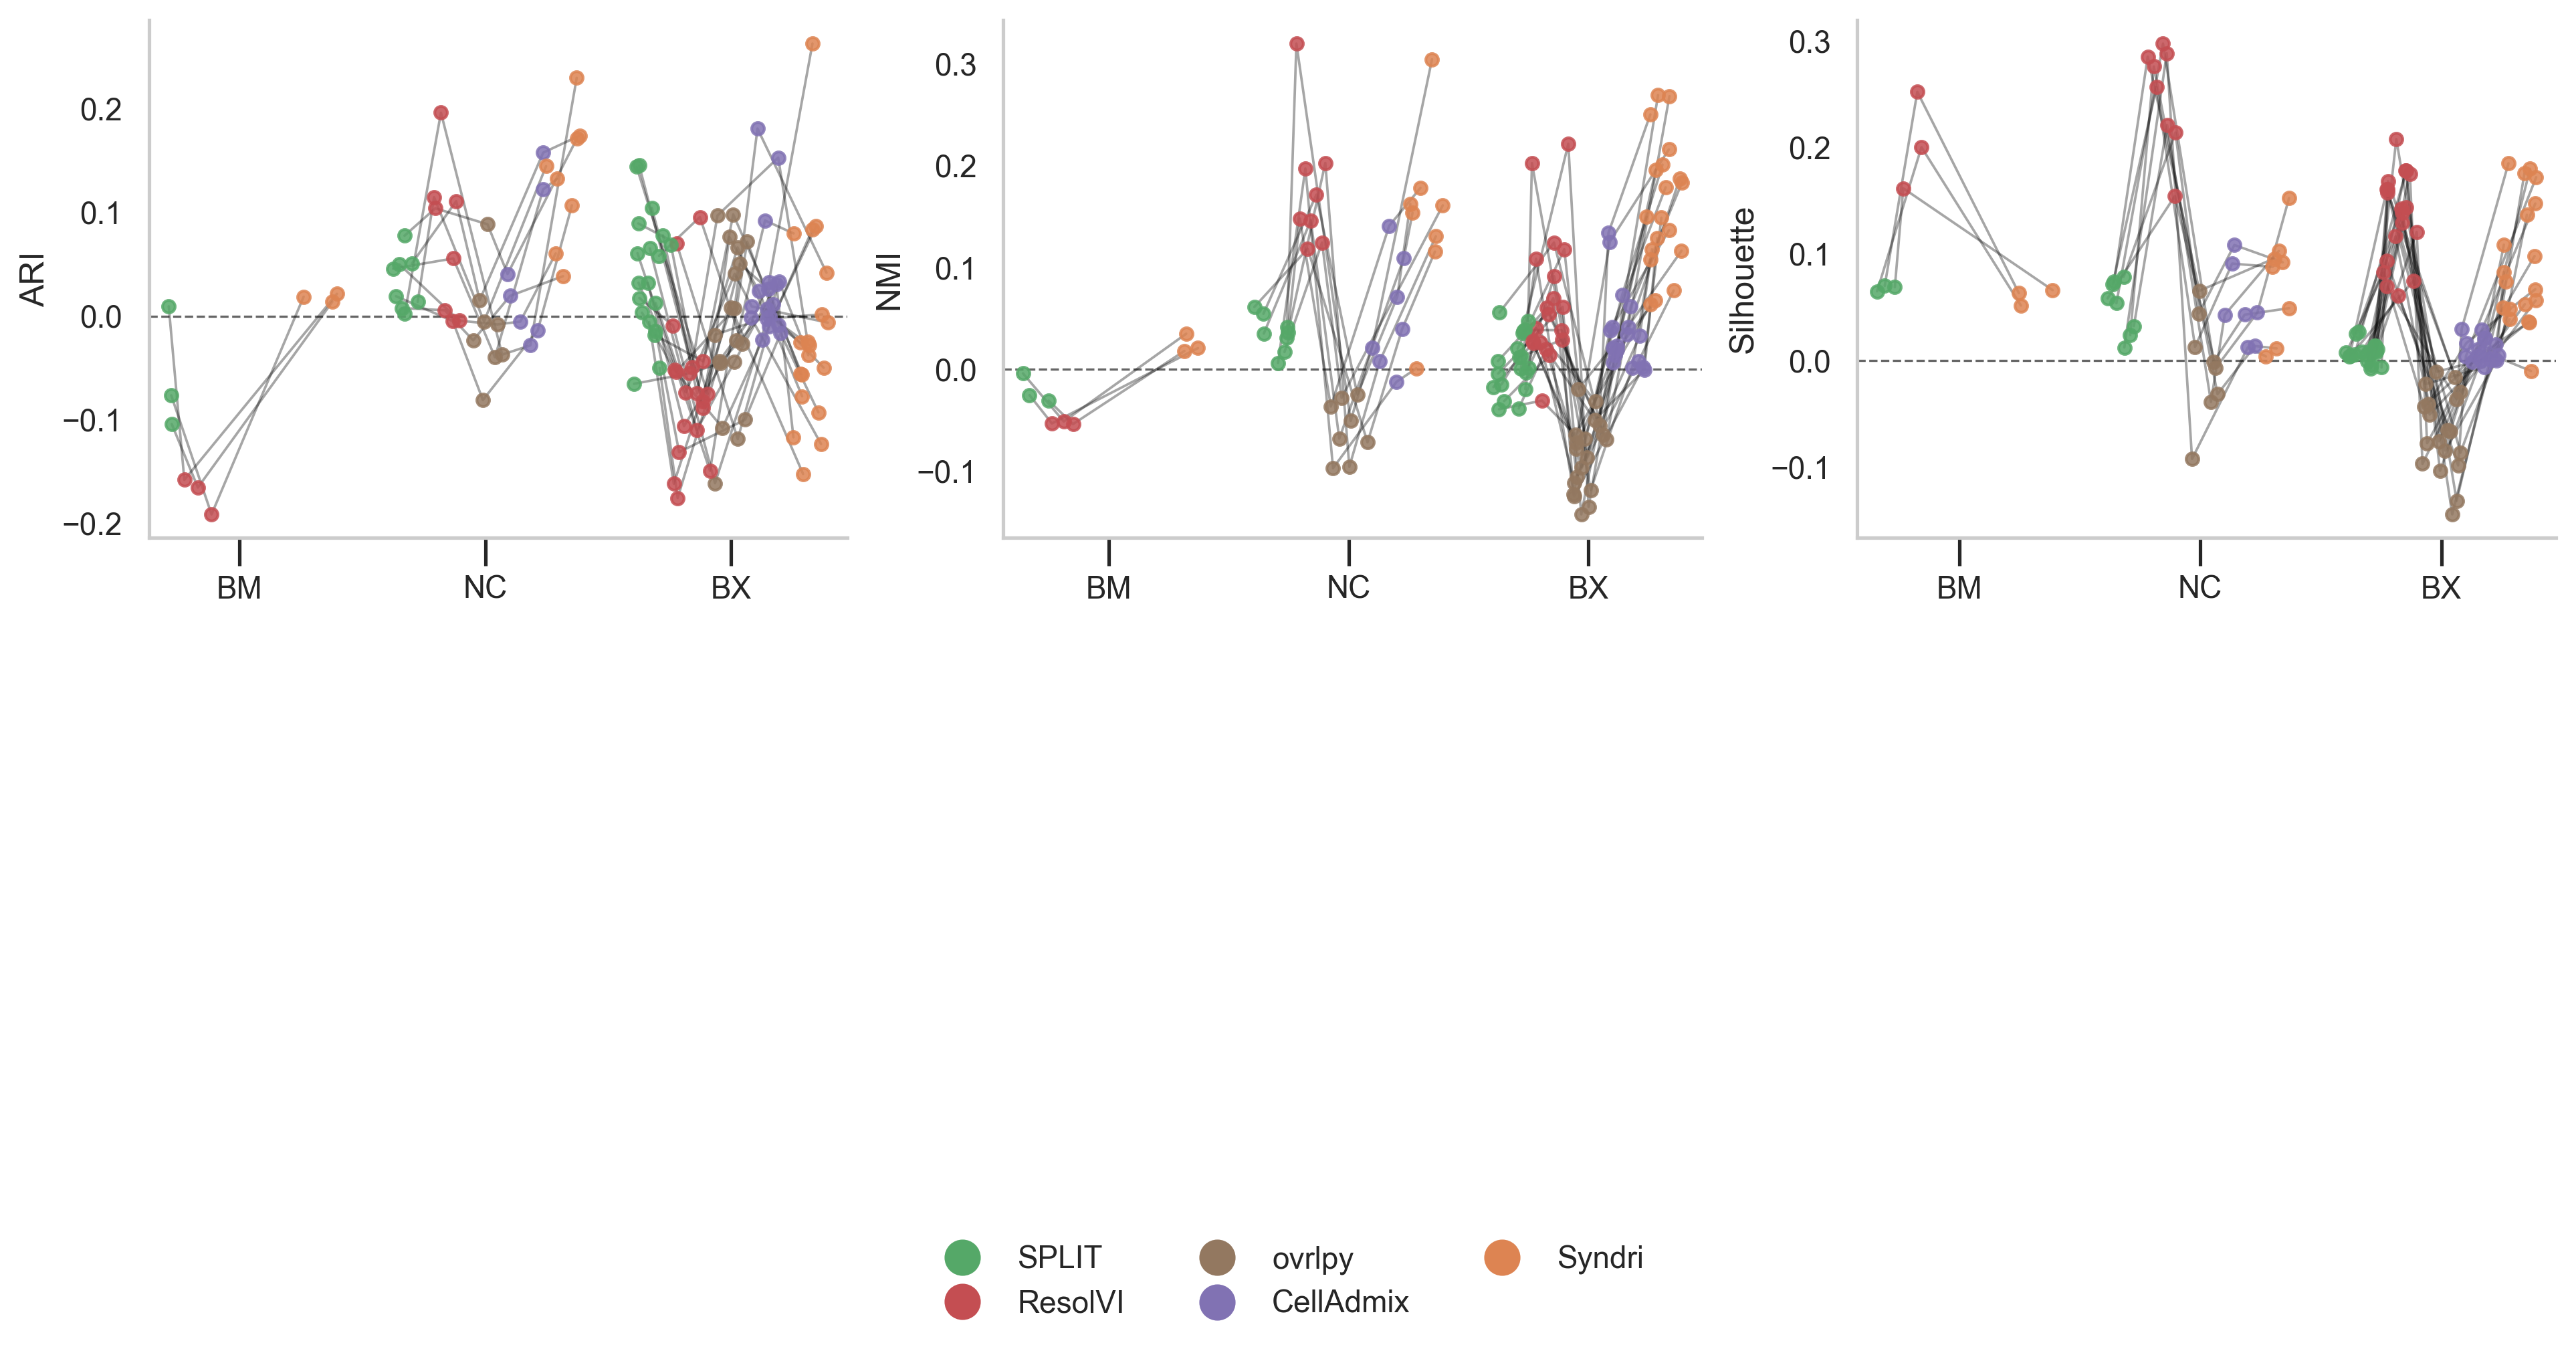

In [14]:
# Pair methods on the same slices within each dataset.
paired_deltas = non_tcell_plot.pivot_table(
    index=["dataset", "slice", "metric"], columns="method",
    values="improvement", aggfunc="mean",
).dropna(subset=["SPLIT", "ResolVI", SYNDRI_LABEL]).copy()
paired_delta_rows = paired_deltas[DELTA_PLOT_ORDER].reset_index()
delta_box_data = (
    paired_delta_rows.melt(
        id_vars=["dataset", "slice", "metric"],
        value_vars=DELTA_PLOT_ORDER,
        var_name="method", value_name="delta",
    ).dropna(subset=["delta"])
)
delta_box_data["dataset_alias"] = delta_box_data["dataset"].map(DATASET_ALIASES)

rng = np.random.default_rng(42)
method_offsets = (
    np.arange(len(DELTA_PLOT_ORDER)) - (len(DELTA_PLOT_ORDER) - 1) / 2
) * (0.8 / len(DELTA_PLOT_ORDER))
fig, axes = plt.subplots(2, 3, figsize=(13, 7), squeeze=False, dpi=300)
for ax, metric in zip(axes.flat, metric_order):
    subset = delta_box_data.loc[delta_box_data["metric"].eq(metric)]
    # sns.boxplot(
    #     data=subset, x="dataset_alias", y="delta", hue="method",
    #     order=dataset_order, hue_order=DELTA_PLOT_ORDER, dodge=True,
    #     palette=COLORS, legend=False, ax=ax, showfliers=False,
    # )
    for dataset_pos, dataset in enumerate(DATASET_TITLES):
        paired = paired_delta_rows.loc[
            paired_delta_rows["dataset"].eq(dataset)
            & paired_delta_rows["metric"].eq(metric),
            DELTA_PLOT_ORDER,
        ]
        for _, row in paired.iterrows():
            available = [method for method in DELTA_PLOT_ORDER if pd.notna(row[method])]
            if not available:
                continue
            positions = [DELTA_PLOT_ORDER.index(method) for method in available]
            x_positions = (
                dataset_pos + method_offsets[positions]
                + rng.uniform(-0.08, 0.08, size=len(available))
            )
            y_positions = row[available].to_numpy(dtype=float)
            if len(available) > 1:
                ax.plot(x_positions, y_positions, color="0", linewidth=0.9,
                        alpha=0.35, zorder=2.5)
            for method, x, y in zip(available, x_positions, y_positions):
                ax.scatter(x, y, s=4.5**2, color=COLORS[method], alpha=0.85, zorder=3)
    ax.axhline(0, color="#666666", linestyle="--", linewidth=0.8, zorder=0)
    ax.set_xlabel("")
    ax.set_ylabel(f"{metric}")
    ax.set_xticks(range(len(dataset_order)), labels=dataset_order)
    ax.tick_params(
        axis="x", top=False, labeltop=False, bottom=True, labelbottom=True, size=10
    )

    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)

for ax in axes.flat[len(metric_order):]:
    ax.remove()

legend_handles = [
    plt.Line2D(
        [0], [0], marker="o", linestyle="", markersize=12,
        markerfacecolor=COLORS[method], markeredgecolor=COLORS[method],
        label=method,
    )
    for method in DELTA_PLOT_ORDER
]
fig.legend(
    handles=legend_handles, loc="lower center", ncol=3,
    bbox_to_anchor=(0.5, 0.01), frameon=False,
)
fig.tight_layout(rect=[0, 0.12, 1, 0.98], h_pad=1.0, w_pad=0.8)
plt.show()

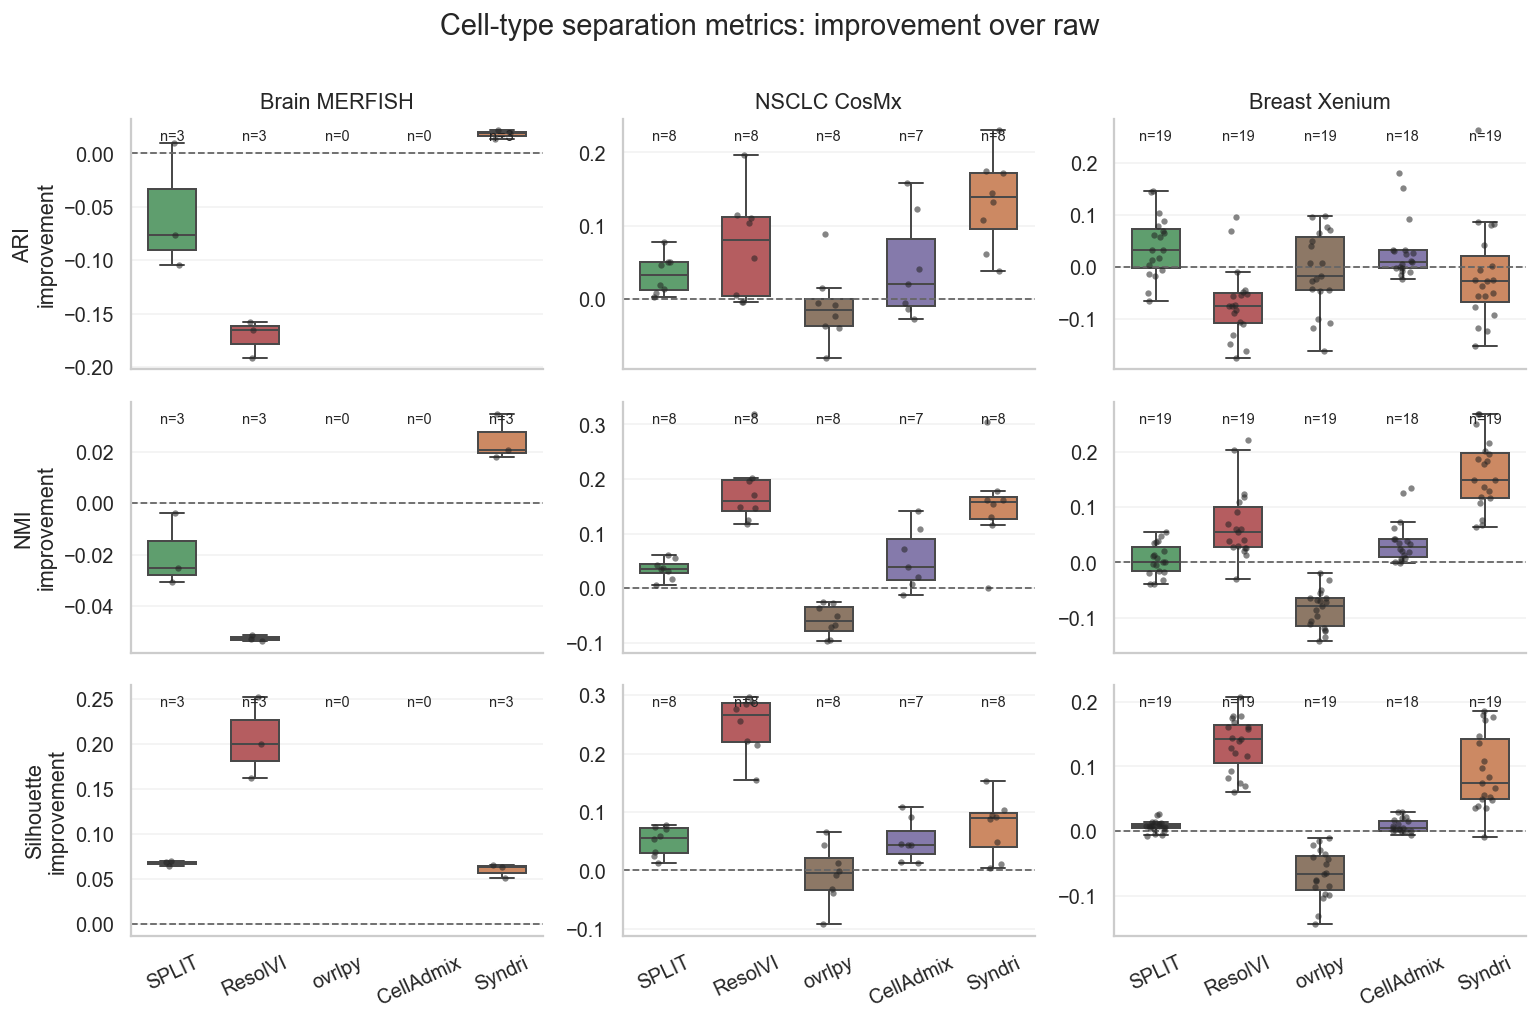

In [15]:
fig, axes = plt.subplots(
    len(metric_order), len(DATASET_TITLES),
    figsize=(4 * len(DATASET_TITLES), 2.6 * len(metric_order)),
    sharex=True, squeeze=False,
)

for col, (dataset, title) in enumerate(DATASET_TITLES.items()):
    for row, metric in enumerate(metric_order):
        ax = axes[row, col]
        subset = non_tcell_plot.loc[
            non_tcell_plot["dataset"].eq(dataset)
            & non_tcell_plot["metric"].eq(metric)
        ]
        boxplot_with_points(
            ax, subset, "method", "improvement", DELTA_PLOT_ORDER, COLORS,
            ylabel=f"{metric}\nimprovement" if col == 0 else "", zero_line=True,
        )
        add_n_labels(ax, subset, "method", DELTA_PLOT_ORDER)
        if row == 0:
            ax.set_title(title, fontweight="bold")
        if row < len(metric_order) - 1:
            ax.tick_params(axis="x", labelbottom=False)
        else:
            ax.tick_params(axis="x", rotation=25)

fig.suptitle("Cell-type separation metrics: improvement over raw", fontsize=16, y=1.005)
fig.tight_layout()
plt.show()




/tmp/ipykernel_11778/2990878579.py:16: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  heatmap_annotations = heatmap_data.applymap(


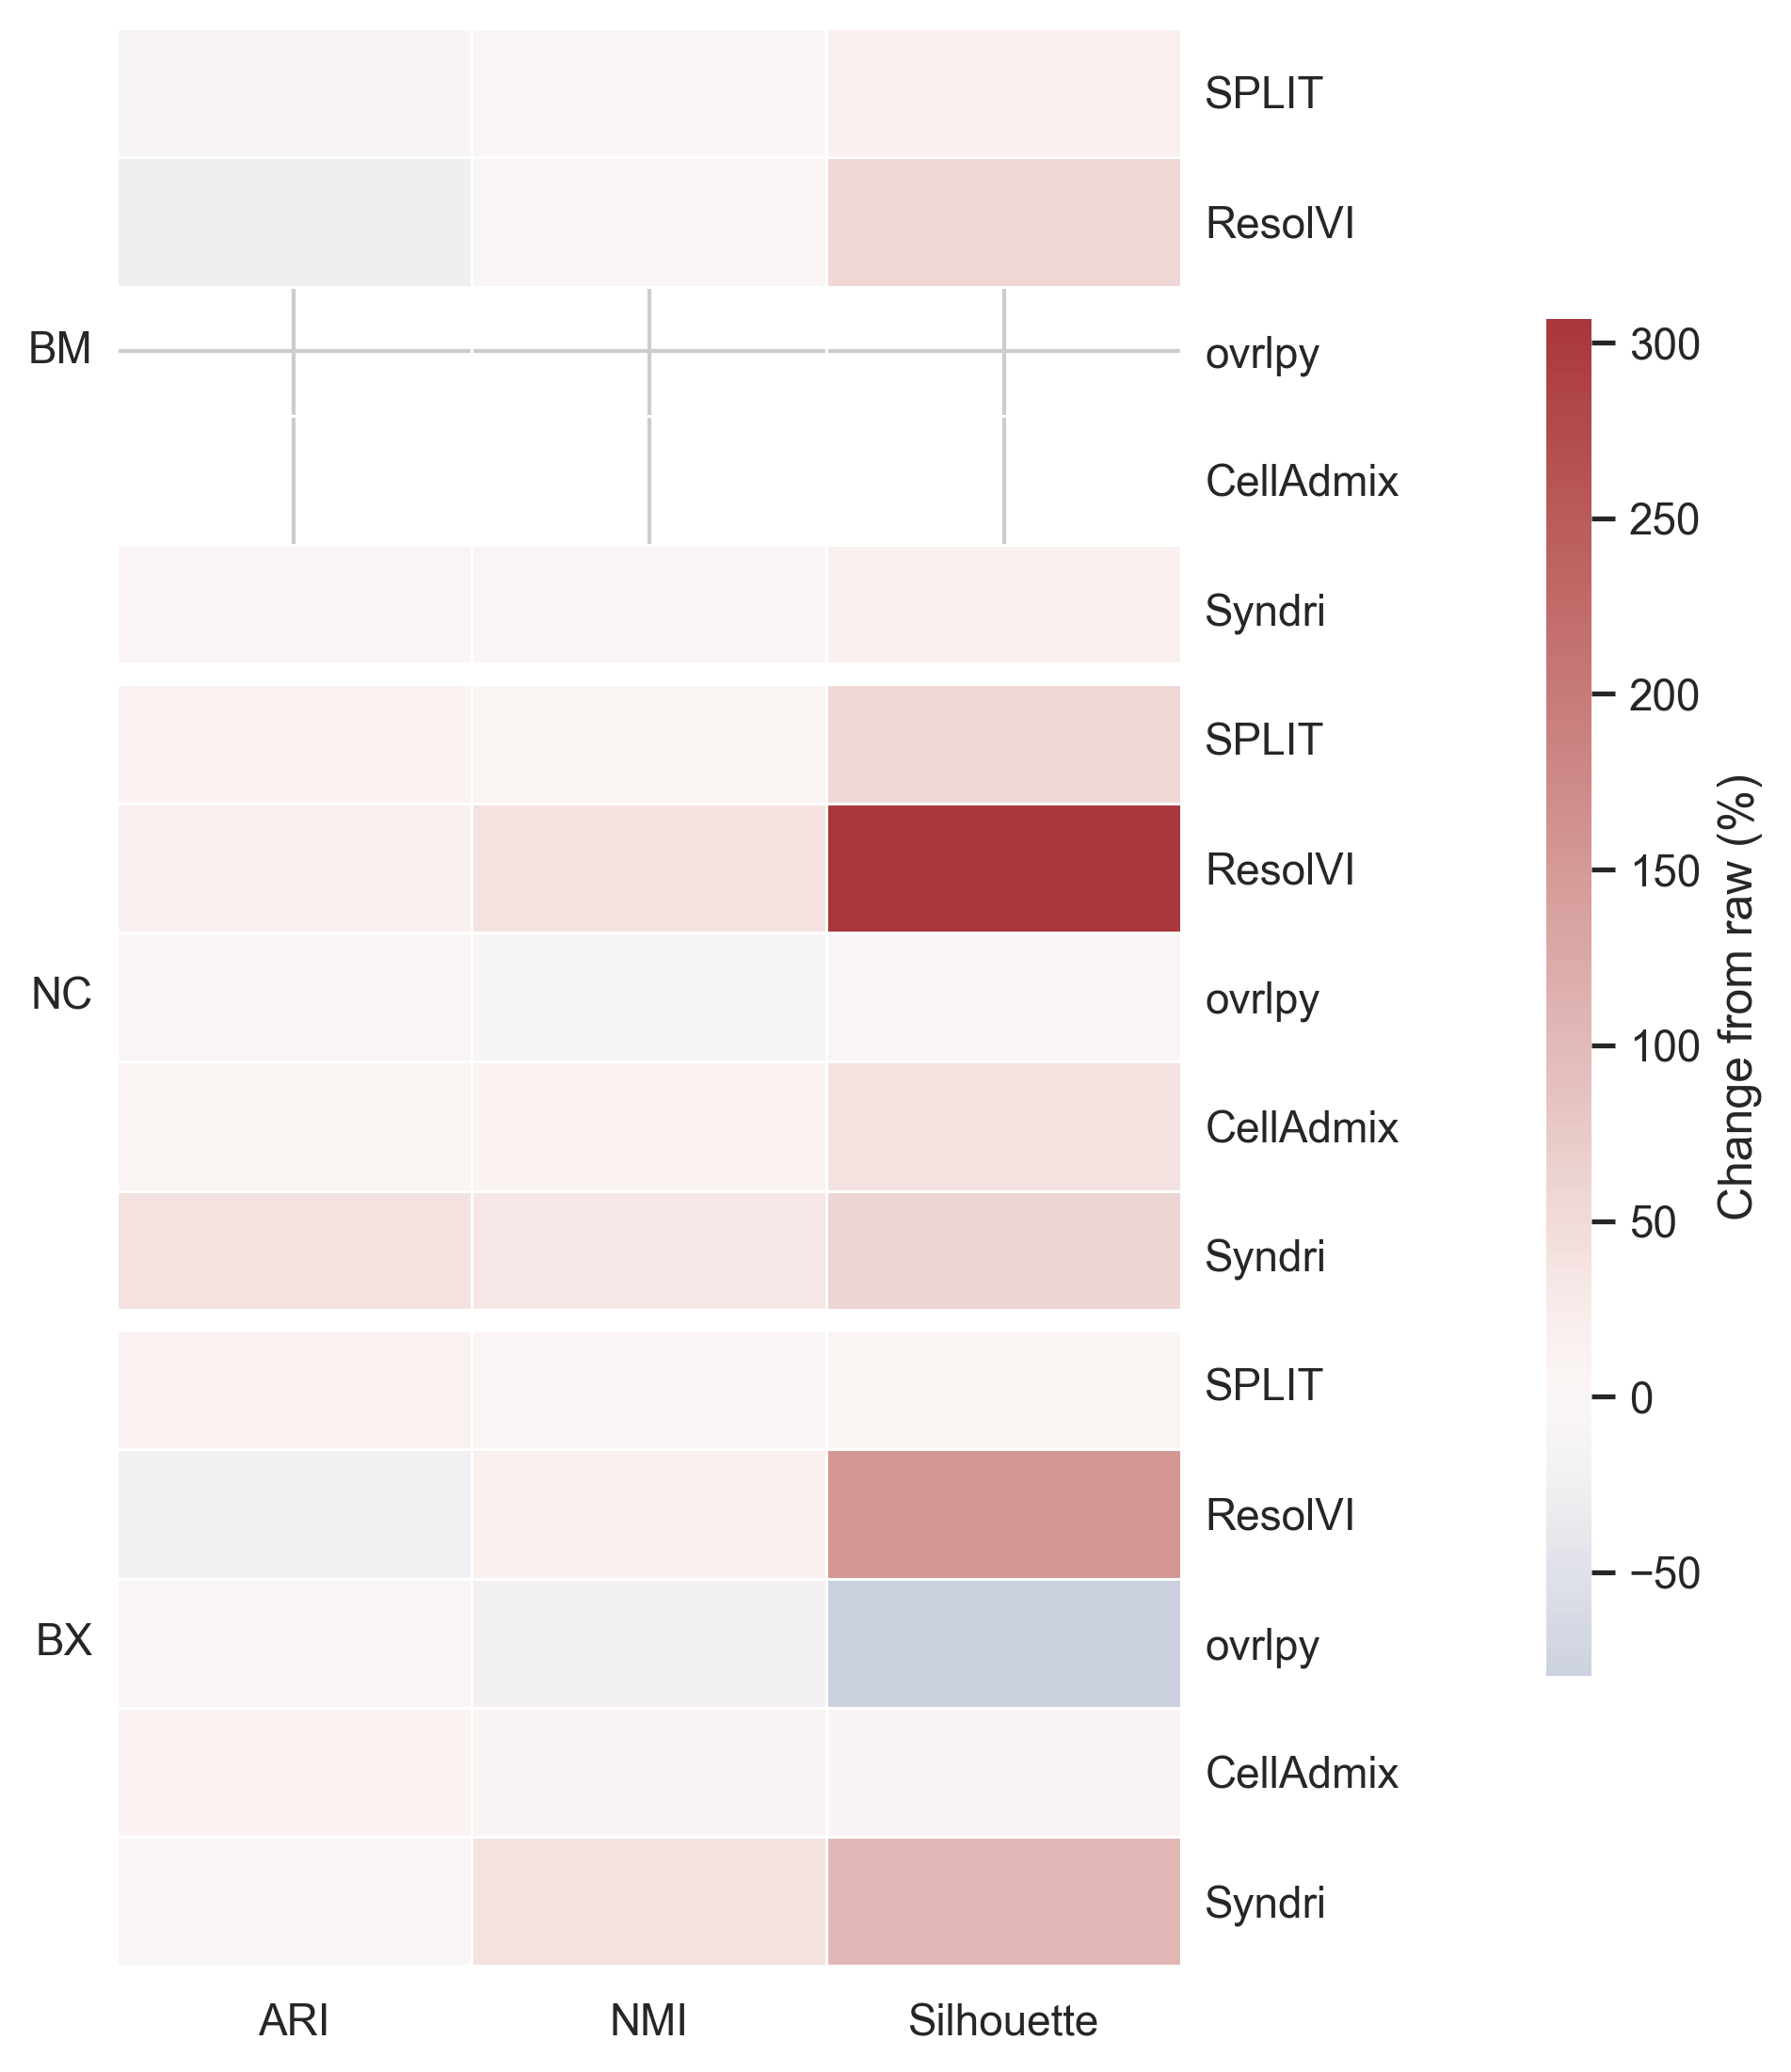

In [16]:
# Mean paired percent change across slices. Positive always indicates improvement.
heatmap_data = (
    non_tcell_percent.groupby(["dataset", "method", "metric"], observed=True)
    ["percent_change"].mean().unstack("metric")
)
heatmap_index = pd.MultiIndex.from_product(
    [DATASET_TITLES, METHOD_ORDER], names=["dataset", "method"]
)
heatmap_data = heatmap_data.reindex(index=heatmap_index, columns=metric_order)
dataset_ticks = (
    np.arange(len(DATASET_TITLES)) * len(METHOD_ORDER)
    + len(METHOD_ORDER) / 2
)
dataset_labels = [DATASET_ALIASES[dataset] for dataset in DATASET_TITLES]
method_labels = heatmap_data.index.get_level_values("method")
heatmap_annotations = heatmap_data.applymap(
    lambda value: f"{value:.1f}" if pd.notna(value) else ""
)

fig, ax = plt.subplots(figsize=(6.5, 7.5), dpi=300)
sns.heatmap(
    heatmap_data, cmap="vlag", center=0, fmt="",
    linewidths=0.7, linecolor="white", annot_kws={"fontsize": 9},
    cbar_kws={
        "orientation": "vertical", "location":"right", "label": "Change from raw (%)",
        "pad": 0.24, "fraction": 0.06, "aspect": 30,"shrink":0.7,
    },
    ax=ax
)
# A narrow white divider separates each dataset group.
for boundary in range(len(METHOD_ORDER), len(heatmap_data), len(METHOD_ORDER)):
    ax.axhline(boundary, color="white", linewidth=6, zorder=10)
ax.set_yticks(dataset_ticks, labels=dataset_labels, rotation=0)
ax.tick_params(axis="y", length=0, pad=6)
ax.xaxis.tick_top()
ax.tick_params(axis="x", top=False, bottom=False, labeltop=False, labelbottom=True)
method_axis = ax.secondary_yaxis("right")
method_axis.set_yticks(np.arange(len(heatmap_data)) + 0.5, labels=method_labels)
method_axis.tick_params(axis="y", length=0, pad=6)
method_axis.spines["right"].set_visible(False)
ax.set_xlabel("")
ax.set_ylabel("")
# ax.set_title("Cell-type separation: percent change from raw", fontweight="bold")
fig.tight_layout()
plt.show()

 ### Syndri versus the best alternative

Scatterplots compare the original metric values for Syndri and the best available alternative among Raw, SPLIT, ResolVI, and the two ovrlpy thresholds per slice. The dashed diagonal marks equal values; axis direction follows whether higher metric values are better. Dataset is shown by color.


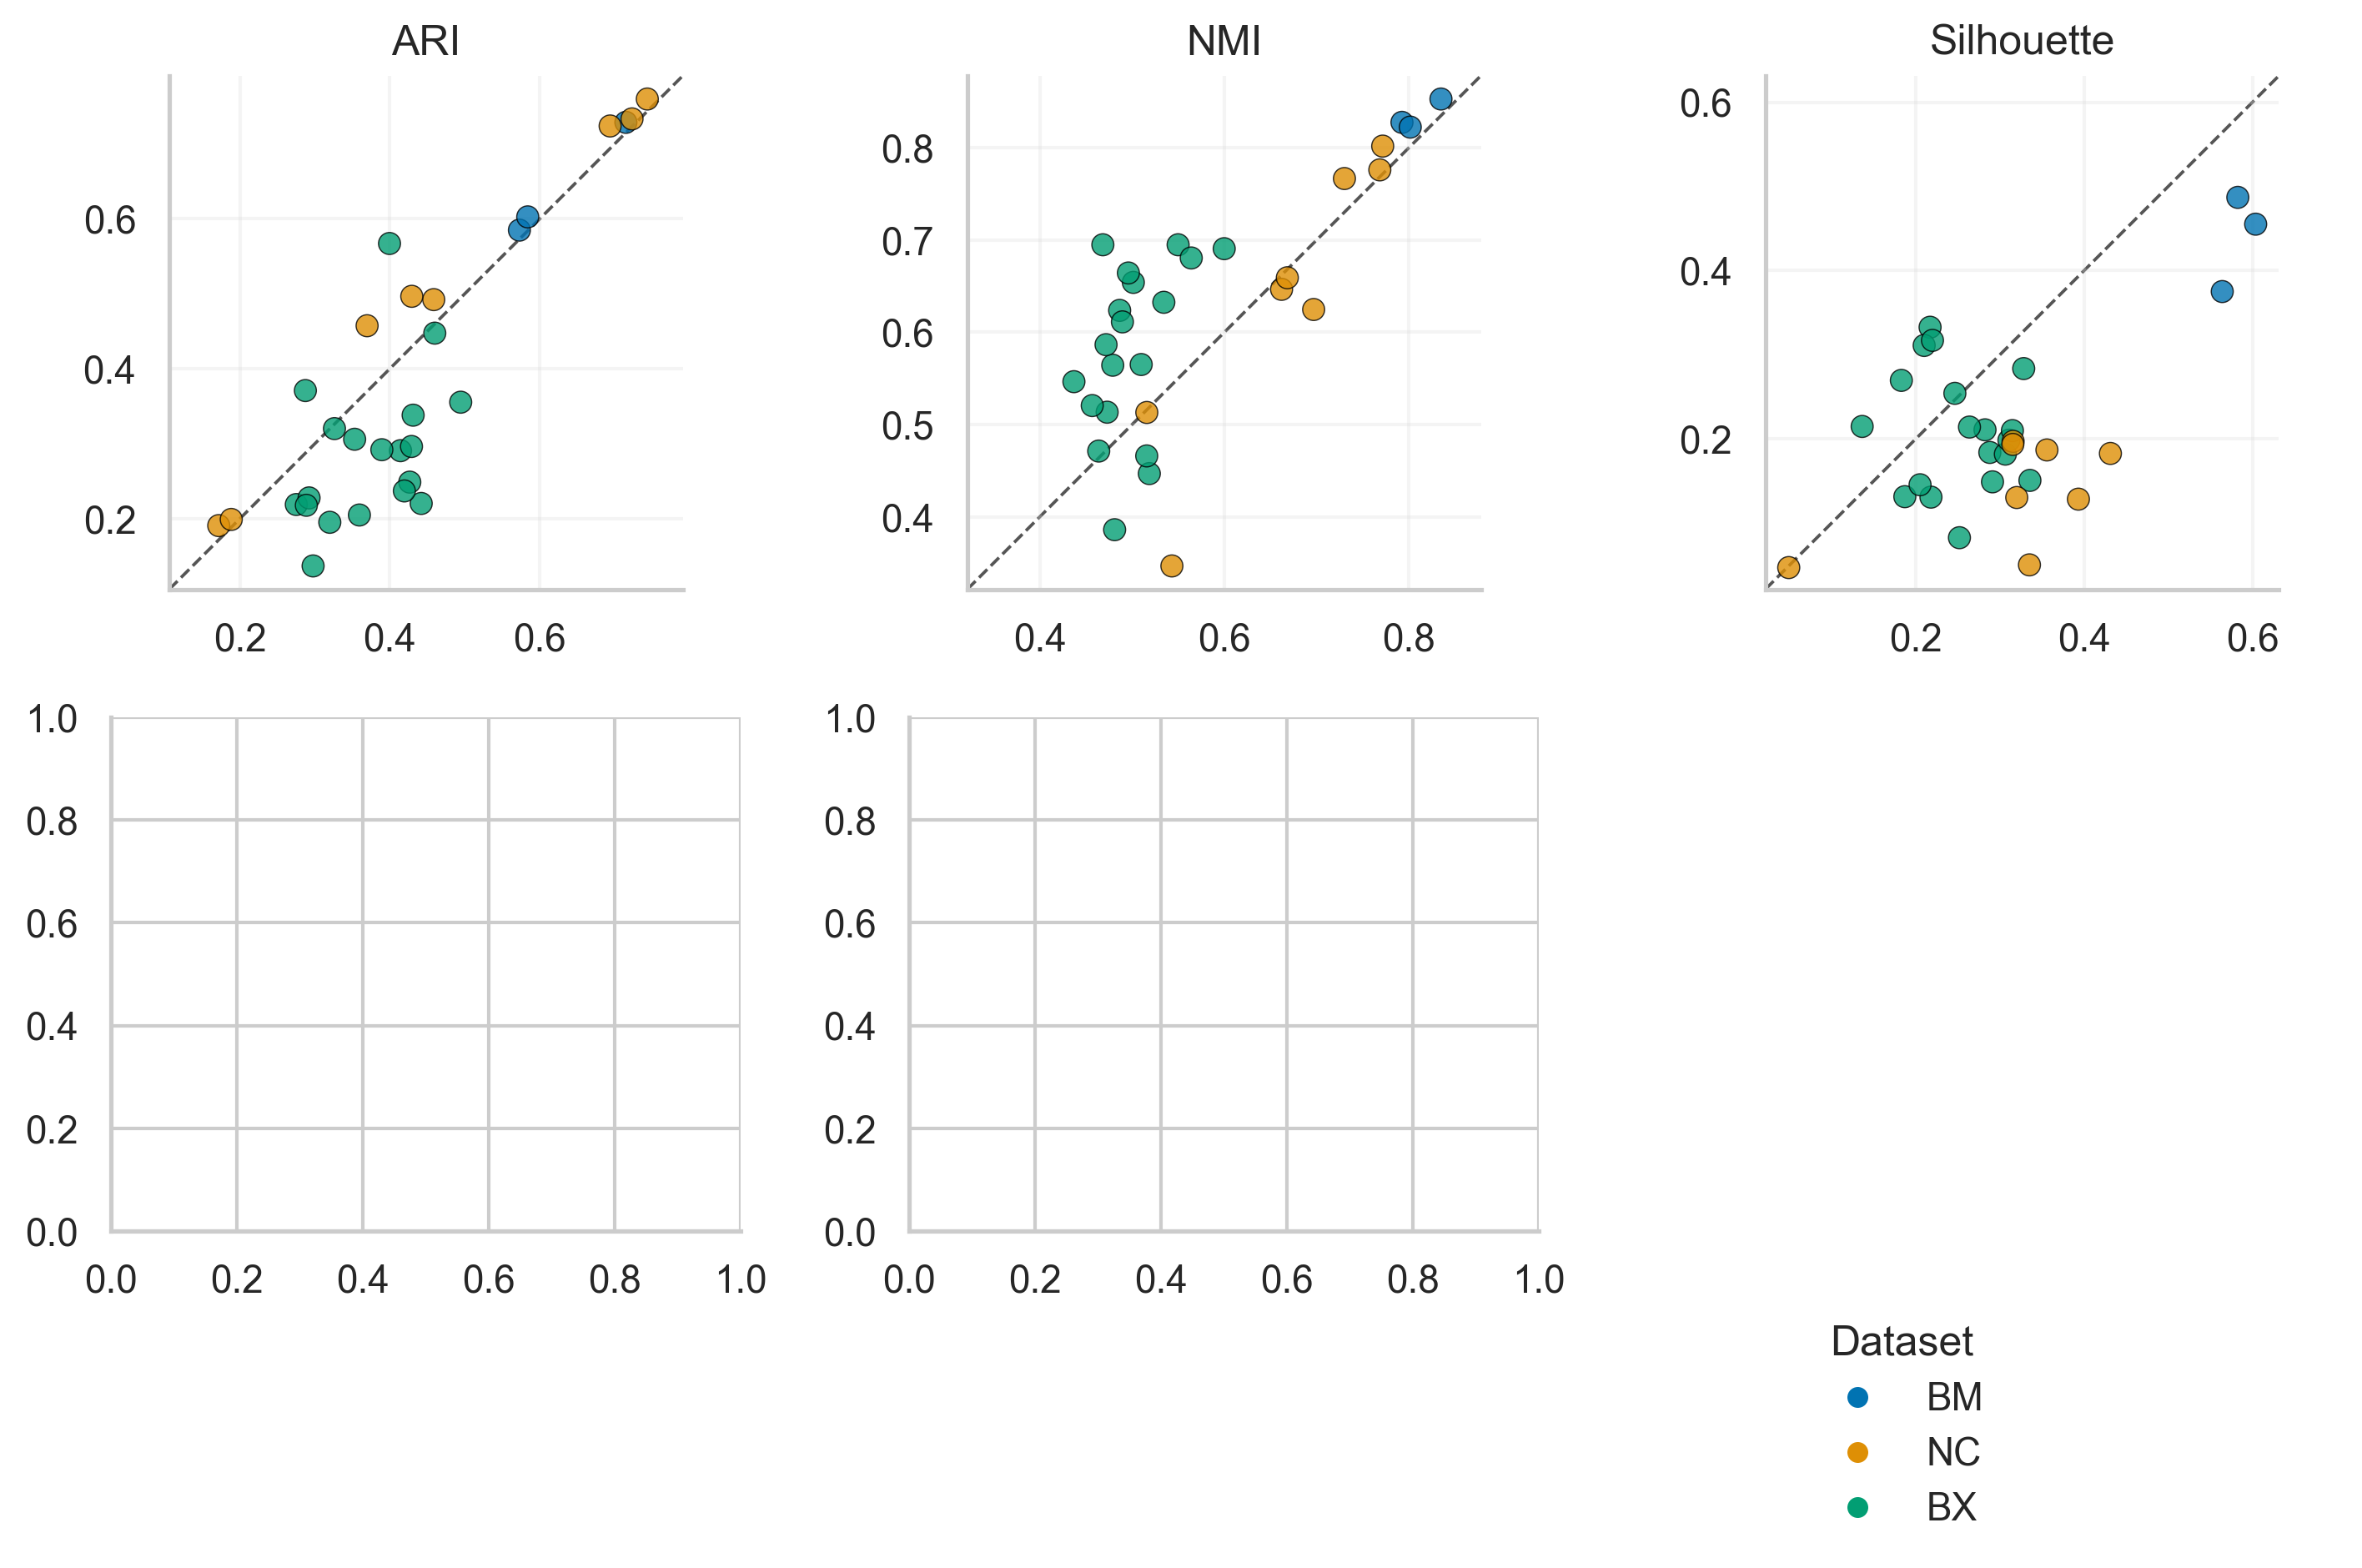

In [17]:
# Pair original metric values per slice and select the best available alternative.
original_values = non_tcell_original.pivot_table(
    index=["dataset", "slice", "metric"], columns="method", values="value", aggfunc="mean"
)
higher_is_better = pd.Series(
    {label: direction for _, (label, direction) in NON_TCELL_METRICS.items()},
    name="direction",
)
alternatives = original_values[ALTERNATIVE_METHODS]
oriented_alternatives = alternatives.mul(
    original_values.index.get_level_values("metric").map(higher_is_better), axis=0
)
best_method = oriented_alternatives.idxmax(axis=1)
alternative_values = alternatives.to_numpy()
row_positions = np.arange(len(original_values))
column_positions = alternatives.columns.get_indexer(best_method)
best_method_values = pd.Series(
    alternative_values[row_positions, column_positions],
    index=original_values.index,
    name="best_alternative_value",
)
syndri_values = original_values[SYNDRI_LABEL].rename("syndri_value")
syndri_best_scatter = pd.concat([syndri_values, best_method_values], axis=1).dropna().reset_index()
syndri_best_scatter["dataset_alias"] = syndri_best_scatter["dataset"].map(DATASET_ALIASES)

fig, axes = plt.subplots(2, 3, figsize=(3.2 * 3, 2 * 3.1), squeeze=False, dpi=300)
for ax, metric in zip(axes.flat, metric_order):
    subset = syndri_best_scatter.loc[syndri_best_scatter["metric"].eq(metric)]
    sns.scatterplot(
        data=subset, x="best_alternative_value", y="syndri_value",
        hue="dataset_alias", hue_order=list(DATASET_ALIASES.values()),
        palette="colorblind", s=40, alpha=0.8, edgecolor="black", linewidth=0.35,
        ax=ax,legend=False
    )
    limits = np.array([*ax.get_xlim(), *ax.get_ylim()])
    low, high = limits.min(), limits.max()
    pad = 0 # 0.04 * (high - low) if high > low else 1
    low, high = low - pad, high + pad
    ax.plot([low, high], [low, high], color="#555555", linestyle="--", linewidth=0.9, zorder=0)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(alpha=0.2)
axes.flat[-1].axis("off")
legend_handles = [
    plt.Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=sns.color_palette("colorblind", n_colors=len(DATASET_ALIASES))[i],
               markeredgecolor="none", label=alias)
    for i, alias in enumerate(DATASET_ALIASES.values())
]
fig.legend(handles=legend_handles, title="Dataset", loc="lower center",
           ncol=1, bbox_to_anchor=(0.8, -0.02), frameon=False)
fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()


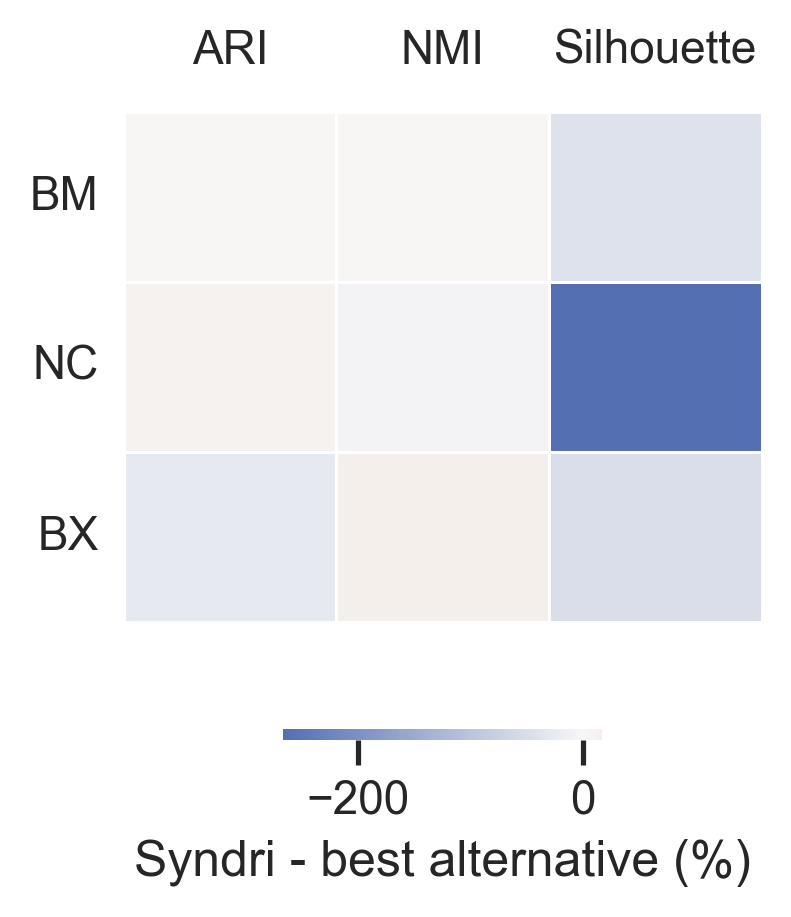

In [18]:
from matplotlib.colors import LinearSegmentedColormap

# Pair on slices with SPLIT, ResolVI, and Syndri; include ovrlpy and CellAdmix where available.
best_alternative = paired_percent[ALTERNATIVE_METHODS[1:]].clip(lower=0).max(axis=1)  # Raw = 0%
syndri_vs_best = (paired_percent[SYNDRI_LABEL] - best_alternative).rename(
    "advantage_percent"
)
syndri_best_heatmap = (
    syndri_vs_best.groupby(level=["dataset", "metric"]).mean()
    .unstack("metric")
    .reindex(index=DATASET_TITLES, columns=metric_order)
)
syndri_split_cmap = LinearSegmentedColormap.from_list(
    "syndri_best_alternative",
    [
        "#5470B3",  # best alternative better
        "#F7F7F7",
        hex[1],  # Syndri better
    ]
)
#  "Raw": "#777777",
#     SYNDRI_LABEL: "#0072B2",
#     "SPLIT": "#6A3D9A"
fig, ax = plt.subplots(figsize=(2.8, 3.2), dpi=300)
sns.heatmap(
    syndri_best_heatmap, cmap=syndri_split_cmap, center=0, annot=False, fmt=".1f",
    linewidths=0.7, linecolor="white", annot_kws={"fontsize": 9},
    cbar_kws={
        "orientation": "horizontal",
        "label": "Syndri - best alternative (%)",
        "pad": 0.16, "fraction": 0.08, "aspect": 30,"shrink":0.5
    },
    ax=ax,
)
ax.set_yticklabels(
    [DATASET_ALIASES[dataset] for dataset in syndri_best_heatmap.index],
    rotation=0,
)
ax.tick_params(axis="y", length=0, pad=6)
ax.xaxis.tick_top()
ax.tick_params(axis="x", top=False, bottom=False, labeltop=True, labelbottom=False)
ax.set_xlabel("")
ax.set_ylabel("")
# ax.set_title("Syndri vs best available alternative", fontsize=11, pad=12)
fig.tight_layout()
plt.show()

## Reference-profile similarity across all cell types and T-cell marker contamination

Reference cosine similarity uses the **same calculation as the original T-cell metric**, now for every annotated cell type in all four datasets: sum counts by type, normalize each pseudobulk profile to 10,000 counts, apply log1p, and calculate cosine similarity over shared spatial/reference genes. Cancer annotations and reference matrices retain the original T-cell settings; aging brain uses donor-specific references and brain MERFISH uses its recorded RCTD reference. Missing reference labels and unavailable methods are reported explicitly. Xenium CellAdmix reference cosine scores are supplemented from the matched CellAdmix corrected-count layers using the same calculation.

For each slice, plotted methods are averaged over the same successfully matched cell-type/reference pairs, with equal weight per type; slices then receive equal weight in the dataset summaries. This is an all-cell-type profile metric, not a per-cell cosine or a measure of within-type heterogeneity. The separate marker-contamination metric remains T-cell-specific and restricted to the two cancer datasets. Historical `tcell_*` table names are retained for downstream plotting compatibility.


In [19]:
def load_tcell(filename):
    frames = []
    for dataset in TCELL_DATASETS:
        competitors = (
            None, "resolvi", "celladmix_k1p5ct",
            *(f"ovrlpy_pixel_correction/{threshold}" for threshold in OVRLPY_METHODS),
        )
        for competitor in competitors:
            frame = load_per_slice_csv(dataset, "tcell", filename, competitor=competitor)
            if not frame.empty:
                frames.append(frame)
    return valid_rows(pd.concat(frames, ignore_index=True)) if frames else pd.DataFrame()


def paired_tcell_improvement(frame, value_col, pair_cols, direction):
    data = frame.copy()
    data["target_removed_fraction"] = pd.to_numeric(
        data.get("target_removed_fraction"), errors="coerce"
    )
    data[value_col] = pd.to_numeric(data[value_col], errors="coerce")
    data = data.loc[np.isfinite(data[value_col])].copy()
    data["method"] = np.select(
        [
            data["condition"].eq("raw_X"),
            fixed_syndri_mask(data, "condition"),
            data["condition"].eq("SPLIT"),
            data["condition"].eq("ResolVI"),
            data["condition"].eq("celladmix_k1p5ct"),
            *(data["condition"].eq(f"ovrlpy_{threshold}") for threshold in OVRLPY_METHODS),
        ],
        ["Raw", SYNDRI_LABEL, "SPLIT", "ResolVI", "CellAdmix", *OVRLPY_METHODS.values()],
        default="",
    )
    data = data.loc[data["method"].ne("")]
    values = data.pivot_table(
        index=["dataset", "slice", *pair_cols],
        columns="method", values=value_col, aggfunc="mean",
    )
    if not {"Raw", *BASE_METHOD_ORDER}.issubset(values.columns):
        return pd.DataFrame()
    values = values.dropna(subset=["Raw", *BASE_METHOD_ORDER])
    results = []
    for method in METHOD_ORDER:
        if method not in values:
            continue
        delta = ((values[method] - values["Raw"]) * direction).dropna().rename("improvement")
        results.append(delta.reset_index().assign(method=method))
    return pd.concat(results, ignore_index=True) if results else pd.DataFrame()


def tcell_original_scale(frame, value_col, metric):
    data = frame.copy()
    data["target_removed_fraction"] = pd.to_numeric(
        data.get("target_removed_fraction"), errors="coerce"
    )
    data[value_col] = pd.to_numeric(data[value_col], errors="coerce")
    data = data.loc[np.isfinite(data[value_col])].copy()
    data["method"] = np.select(
        [
            data["condition"].eq("raw_X"),
            fixed_syndri_mask(data, "condition"),
            data["condition"].eq("SPLIT"),
            data["condition"].eq("ResolVI"),
            data["condition"].eq("celladmix_k1p5ct"),
            *(data["condition"].eq(f"ovrlpy_{threshold}") for threshold in OVRLPY_METHODS),
        ],
        ["Raw", SYNDRI_LABEL, "SPLIT", "ResolVI", "CellAdmix", *OVRLPY_METHODS.values()],
        default="",
    )
    return (
        data.loc[data["method"].ne("")]
        .groupby(["dataset", "slice", "method"], observed=True)[value_col]
        .mean().rename("value").reset_index().assign(metric=metric)
    )

# Same pseudobulk cosine calculation as the former T-cell reference metric,
# expanded to all annotated cell types and all four datasets.
reference_frames = []
for dataset in DATASET_TITLES:
    root = ROOT / dataset / 'results/metrics' / REFERENCE_COSINE_RUN / 'all_cell_types'
    for path in sorted(root.glob('*/reference_cosine_similarity.csv')):
        if (path.parent/'complete.json').exists():
            reference_frames.append(pd.read_csv(path))
if not reference_frames:
    raise FileNotFoundError(f'No completed all-cell-type cosine metrics: {REFERENCE_COSINE_RUN}')
cosine_all_rows = pd.concat(reference_frames,ignore_index=True)
# The original all-type run predates the Xenium CellAdmix corrections. Append
# their matched-layer results from the supplemental Slurm run when available.
XENIUM_CELLADMIX_REFERENCE_COSINE_PATH = Path(
    '/home/jwinchel/Syndri/context_analysis/results/'
    'xenium_celladmix_reference_cosine_20261021/reference_cosine_similarity.csv'
)
if XENIUM_CELLADMIX_REFERENCE_COSINE_PATH.is_file():
    xenium_celladmix_cosine = pd.read_csv(
        XENIUM_CELLADMIX_REFERENCE_COSINE_PATH, low_memory=False
    )
    # The supplemental Slurm run also recomputes Raw/SPLIT/Syndri. Those
    # methods already exist in the original all-cell-type run, so append only
    # CellAdmix to avoid duplicate method/cell-type rows in downstream pivots.
    xenium_celladmix_cosine = xenium_celladmix_cosine.loc[
        xenium_celladmix_cosine['method'].eq('CellAdmix')
    ].copy()
    cosine_all_rows = pd.concat(
        [cosine_all_rows, xenium_celladmix_cosine], ignore_index=True
    )
    print('Loaded supplemental Xenium CellAdmix reference rows:', len(xenium_celladmix_cosine))
cosine_all_rows = cosine_all_rows.loc[cosine_all_rows.method.isin(COUNT_METHOD_ORDER)].copy()
reference_original_rows = []
reference_delta_rows = []
reference_coverage = []
for (dataset,slice_id),group in cosine_all_rows.groupby(['dataset','slice'],observed=True):
    methods = [method for method in COUNT_METHOD_ORDER if method in set(group.method)]
    successful = group.loc[group.status.eq('ok') & group.cosine_similarity.notna()]
    values = successful.pivot(index=['spatial_cell_type','reference_cell_type'],columns='method',values='cosine_similarity')
    values = values.reindex(columns=methods)
    matched = values.dropna(subset=methods)
    reference_coverage.append(dict(dataset=dataset,slice=slice_id,
        available_methods=', '.join(methods),n_types_before_matching=len(values),
        n_shared_reference_types=len(matched)))
    if matched.empty or 'Raw' not in methods:
        continue
    for method in methods:
        reference_original_rows.append(dict(dataset=dataset,slice=slice_id,method=method,
            metric='Reference cosine similarity',value=matched[method].mean()))
        if method!='Raw':
            reference_delta_rows.append(dict(dataset=dataset,slice=slice_id,method=method,
                metric='Reference cosine similarity',improvement=(matched[method]-matched['Raw']).mean()))
reference_cosine_original = pd.DataFrame(reference_original_rows)
cosine_plot = pd.DataFrame(reference_delta_rows)
reference_cosine_coverage = pd.DataFrame(reference_coverage)
display(reference_cosine_coverage)
# Only the marker-contamination metric remains restricted to T cells/cancer.
contamination = load_tcell('tcell_contamination_metrics.csv')
contamination = contamination[~contamination['tissue'].str.startswith('cosmx')]
contamination_plot = paired_tcell_improvement(
    contamination, "marker_overlap_frac",
    ["target_cell_type_i", "contaminating_cell_type_j"], direction=-1,
)
contamination_plot["metric"] = "Reduced marker contamination"

tcell_plot = pd.concat([cosine_plot, contamination_plot], ignore_index=True)
tcell_slice_plot = (
    tcell_plot.groupby(["dataset", "slice", "method", "metric"], observed=True)
    ["improvement"].mean().reset_index()
)
tcell_original = pd.concat([
    reference_cosine_original,
    tcell_original_scale(contamination, "marker_overlap_frac", "Marker overlap fraction"),
], ignore_index=True)
print(tcell_slice_plot.groupby(["dataset", "method"])["slice"].nunique())


Loaded supplemental Xenium CellAdmix reference rows: 270


,dataset,slice,available_methods,n_types_before_matching,n_shared_reference_types
0,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,"Raw, SPLIT, ResolVI, Syndri",18,18
1,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.002,"Raw, SPLIT, ResolVI, Syndri",17,17
2,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.003,"Raw, SPLIT, ResolVI, Syndri",25,25
3,breast_xenium,GSM9509156_breast_breast_B17_B17_rctd_annotated,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",15,15
4,breast_xenium,GSM9509157_breast_breast_B16_B16_rctd_annotated,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",15,15
5,breast_xenium,GSM9509158_breast_breast_B15_B15_rctd_annotated,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",15,15
6,breast_xenium,GSM9509159_breast_breast_B14_B14_rctd_annotated,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",15,15
7,breast_xenium,GSM9509160_breast_breast_B2_B2_rctd_annotated,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",15,15
8,breast_xenium,GSM9509161_breast_breast_B13_B13_rctd_annotated,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",15,15
9,breast_xenium,GSM9509162_breast_breast_B12_B12_rctd_annotated,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",15,15


breast_xenium/tcell/tcell_contamination_metrics.csv: hard-zero Syndri slices = 19
nsclc_cosmx/tcell/tcell_contamination_metrics.csv: hard-zero Syndri slices = 8
dataset        method   
brain_merfish  ResolVI       3
               SPLIT         3
               Syndri        3
breast_xenium  CellAdmix    18
               ResolVI      19
               SPLIT        19
               Syndri       19
               ovrlpy       19
nsclc_cosmx    CellAdmix     7
               ResolVI       8
               SPLIT         8
               Syndri        8
               ovrlpy        8
Name: slice, dtype: int64


/tmp/ipykernel_11778/4009469486.py:18: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_11778/4009469486.py:18: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


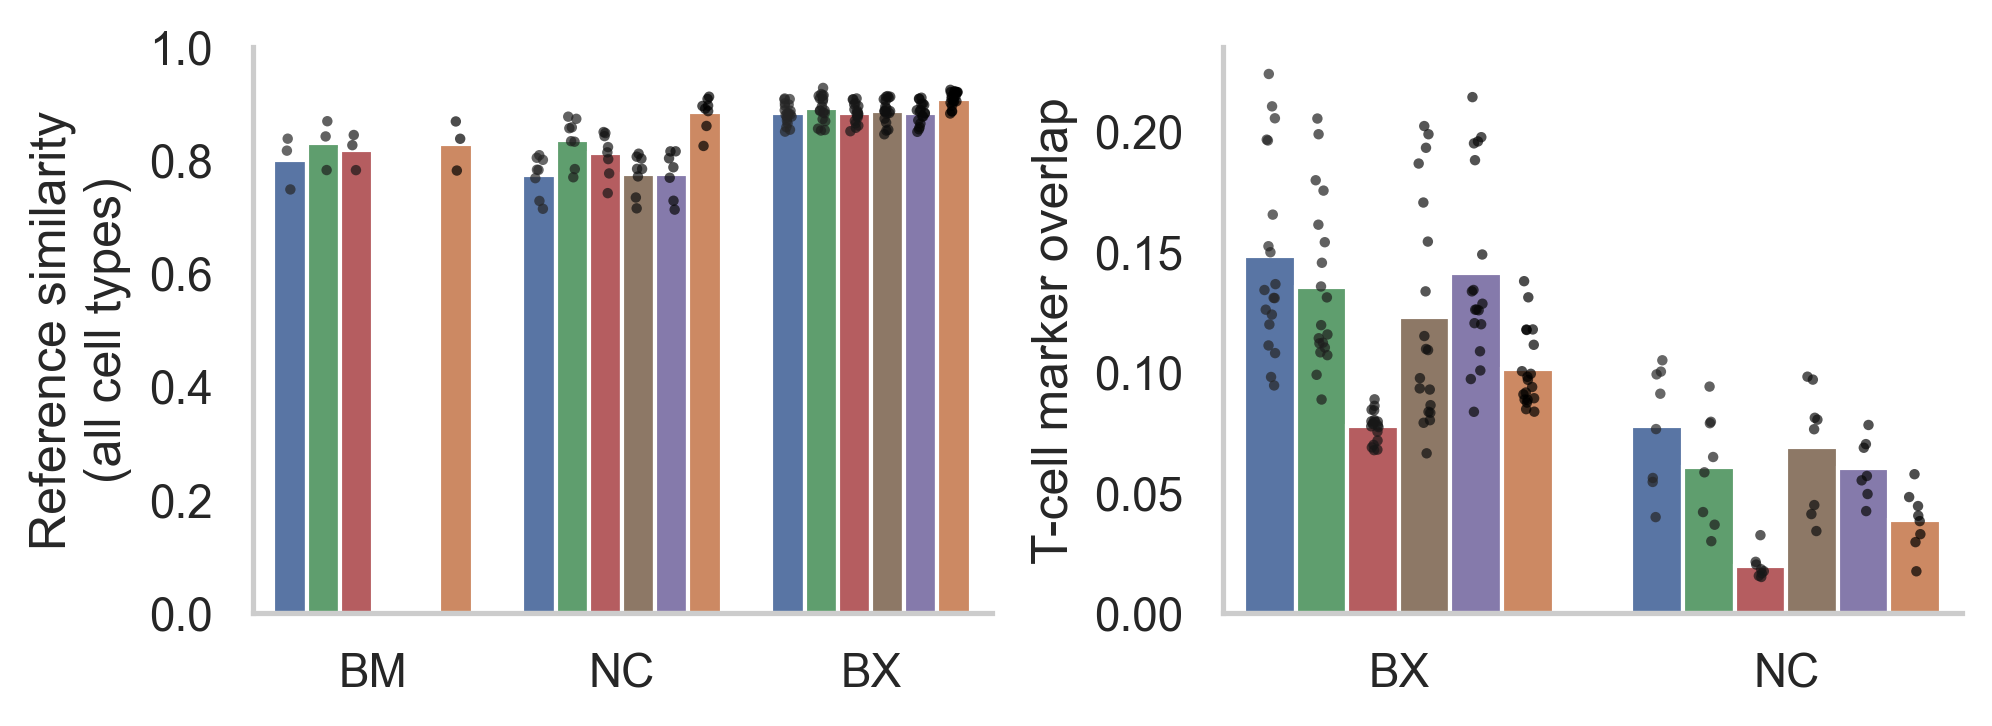

In [20]:
tcell_original_metric_order = [
    "Reference cosine similarity", "Marker overlap fraction",
]
ylabels = ["Reference similarity\n(all cell types)", "T-cell marker overlap"]
tcell_dataset_order = [DATASET_ALIASES[dataset] for dataset in TCELL_DATASETS]
tcell_original_plot = tcell_original.assign(
    dataset_alias=tcell_original["dataset"].map(DATASET_ALIASES)
)
fig, axes = plt.subplots(1, len(tcell_original_metric_order), figsize=(6.8, 3), squeeze=False,dpi=300)
for i, (ax, metric) in enumerate(zip(axes.flat, tcell_original_metric_order)):
    subset = tcell_original_plot.loc[tcell_original_plot["metric"].eq(metric)]
    panel_dataset_order = [DATASET_ALIASES[d] for d in (DATASET_TITLES if metric=="Reference cosine similarity" else TCELL_DATASETS)]
    sns.barplot(
        data=subset, x="dataset_alias", y="value", hue="method",
        order=panel_dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        palette=COLORS, legend=False, ax=ax, errorbar=None
    )
    sns.stripplot(
        data=subset, x="dataset_alias", y="value", hue="method",
        order=panel_dataset_order, hue_order=COUNT_METHOD_ORDER, dodge=True,
        color="black", size=2.5, alpha=0.7, legend=False, ax=ax, jitter=True,
    )
    if i==0:
        ax.set_ylim([0,1.0])
    ax.set(xlabel="", ylabel=ylabels[i])
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)
# fig.legend(handles=[
#     plt.Line2D([0], [0], marker="o", linestyle="", markersize=6,
#                markerfacecolor=COLORS[method], markeredgecolor=COLORS[method], label=method)
#     for method in COUNT_METHOD_ORDER
# ], loc="lower center", ncol=3,
#            bbox_to_anchor=(0.5, 0.01), frameon=False)
# fig.suptitle('T-cells')
fig.tight_layout(rect=[0, 0.14, 1, 1], w_pad=0.8)

plt.show()

/tmp/ipykernel_11778/2919266258.py:14: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_11778/2919266258.py:14: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


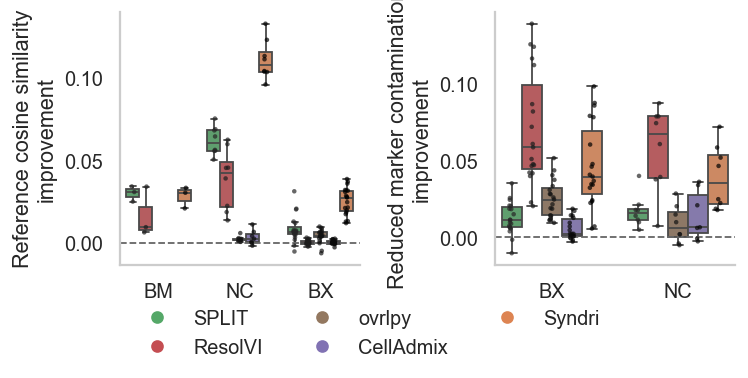

In [21]:
tcell_metric_order = ["Reference cosine similarity", "Reduced marker contamination"]
tcell_improvement_plot = tcell_slice_plot.assign(
    dataset_alias=tcell_slice_plot["dataset"].map(DATASET_ALIASES)
)
fig, axes = plt.subplots(1, len(tcell_metric_order), figsize=(6, 3), squeeze=False)
for ax, metric in zip(axes.flat, tcell_metric_order):
    subset = tcell_improvement_plot.loc[tcell_improvement_plot["metric"].eq(metric)]
    panel_dataset_order = [DATASET_ALIASES[d] for d in (DATASET_TITLES if metric=="Reference cosine similarity" else TCELL_DATASETS)]
    sns.boxplot(
        data=subset, x="dataset_alias", y="improvement", hue="method",
        order=panel_dataset_order, hue_order=DELTA_PLOT_ORDER, dodge=True,
        palette=COLORS, legend=False, ax=ax, showfliers=False,
    )
    sns.stripplot(
        data=subset, x="dataset_alias", y="improvement", hue="method",
        order=panel_dataset_order, hue_order=DELTA_PLOT_ORDER, dodge=True,
        color="black", size=2.5, alpha=0.7, legend=False, ax=ax, jitter=True,
    )
    ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
    ax.set(xlabel="", ylabel=f"{metric}\nimprovement")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.03)
fig.legend(handles=[
    plt.Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=COLORS[method], markeredgecolor=COLORS[method], label=method)
    for method in DELTA_PLOT_ORDER
], loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, 0.01), frameon=False)
fig.tight_layout(rect=[0, 0.14, 1, 1], w_pad=0.8)
plt.show()


## Expression retained after cleaning

These are absolute per-slice count summaries rather than improvements from raw.


/tmp/ipykernel_11778/1275819946.py:101: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_11778/1275819946.py:101: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_11778/1275819946.py:101: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


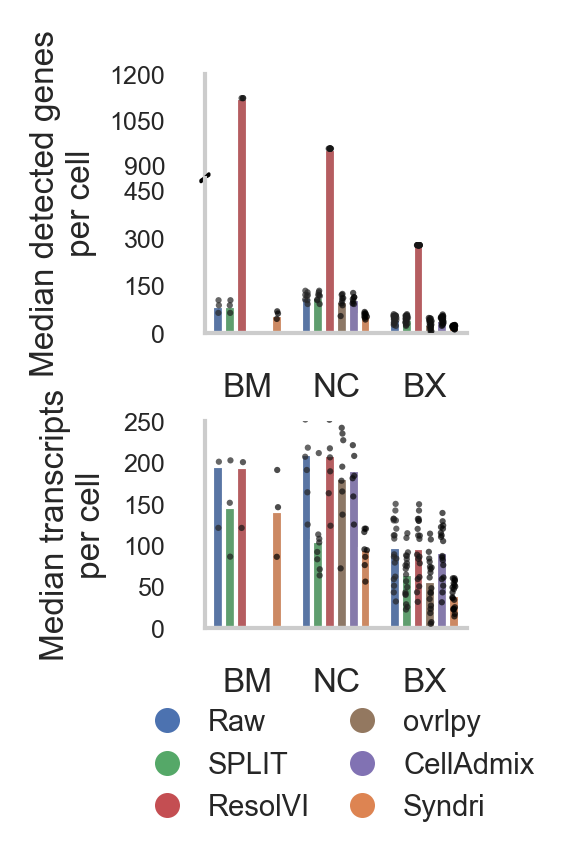

In [22]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
font_path = "/home/jwinchel/fonts/ARIAL.TTF"
fm.fontManager.addfont(font_path)

mpl.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "Arial"

REPO = Path("/home/jwinchel/Syndri")
FIGURE_DIR = REPO / "figures" / "outputs"

COUNT_METRICS = {
    "median_genes_per_cell": "Median detected genes\nper cell",
    "median_transcripts_per_cell": "Median transcripts\nper cell",
}

count_data = non_tcell.loc[
    non_tcell["method"].isin(COUNT_METHOD_ORDER),
    ["dataset", "slice", "method", *COUNT_METRICS],
].copy()

count_plot = count_data.assign(
    dataset_alias=count_data["dataset"].map(DATASET_ALIASES)
)

dataset_order = [
    DATASET_ALIASES[dataset]
    for dataset in DATASET_TITLES
]

# ------------------------------------------------------------------
# Figure: one column, two main plots
#
# Top plot:
#   Median detected genes per cell
#   -> internally uses a broken y-axis
#
# Bottom plot:
#   Median transcripts per cell
# ------------------------------------------------------------------
fig = plt.figure(figsize=(1.15, 2.25), dpi=300)

# Outer grid controls the two main plots
outer_grid = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[1.25, 1.0],
    hspace=0.38,
)

# Nested grid for the broken y-axis in the detected-genes plot
genes_grid = outer_grid[0].subgridspec(
    nrows=2,
    ncols=1,
    height_ratios=[2, 3],
    hspace=0,
)

genes_top = fig.add_subplot(genes_grid[0])
genes_bottom = fig.add_subplot(
    genes_grid[1],
    sharex=genes_top,
)

# Bottom main plot
transcripts_ax = fig.add_subplot(outer_grid[1])

# ------------------------------------------------------------------
# Helper for plotting bars + slice-level points
# ------------------------------------------------------------------
def plot_metric(ax, metric):
    subset = count_plot.dropna(subset=[metric])

    sns.barplot(
        data=subset,
        x="dataset_alias",
        y=metric,
        hue="method",
        order=dataset_order,
        hue_order=COUNT_METHOD_ORDER,
        dodge=True,
        palette=COLORS,
        legend=False,
        errorbar=None,
        ax=ax,
    )

    random_state = np.random.get_state()
    np.random.seed(0)

    sns.stripplot(
        data=subset,
        x="dataset_alias",
        y=metric,
        hue="method",
        order=dataset_order,
        hue_order=COUNT_METHOD_ORDER,
        dodge=True,
        color="black",
        size=1.5,
        alpha=0.7,
        legend=False,
        ax=ax,
        jitter=True,
    )

    np.random.set_state(random_state)

    ax.set(xlabel="", ylabel="")
    ax.grid(False)
    ax.margins(x=0.03)

    # Do NOT use set_xticklabels / set_yticklabels here.
    ax.tick_params(axis="y", labelsize=6)
    ax.tick_params(axis="x", labelsize=8)

    for spine in ax.spines.values():
        spine.set_linewidth(1)


# ------------------------------------------------------------
# Detected genes: broken y-axis
# ------------------------------------------------------------
for ax in [genes_top, genes_bottom]:
    plot_metric(ax, "median_genes_per_cell")

genes_top.set_ylim(860, 1200)
genes_top.set_yticks([900, 1050, 1200])

genes_bottom.set_ylim(0, 490)
genes_bottom.set_yticks([0, 150, 300, 450])

genes_top.spines["bottom"].set_visible(False)
genes_bottom.spines["top"].set_visible(False)

genes_top.tick_params(
    axis="x",
    which="both",
    bottom=False,
    labelbottom=False,
)

# Broken-axis markers
d = 0.015

genes_top.plot(
    [-d, +d],
    [-0.025, +0.025],
    transform=genes_top.transAxes,
    color="black",
    linewidth=0.8,
    clip_on=False,
)

genes_bottom.plot(
    [-d, +d],
    [1 - 0.025, 1 + 0.025],
    transform=genes_bottom.transAxes,
    color="black",
    linewidth=0.8,
    clip_on=False,
)

fig.text(
    -0.19,
    0.79,
    COUNT_METRICS["median_genes_per_cell"],
    va="center",
    ha="center",
    rotation="vertical",
    fontsize=8,
)


# ------------------------------------------------------------
# Transcripts per cell
# ------------------------------------------------------------
plot_metric(
    transcripts_ax,
    "median_transcripts_per_cell",
)

transcripts_ax.set_ylim(0, 250)
transcripts_ax.set_yticks([0, 50, 100, 150, 200, 250])

transcripts_ax.set_ylabel(
    COUNT_METRICS["median_transcripts_per_cell"],
    fontsize=8,
)


# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------
handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=5,
        markerfacecolor=COLORS[method],
        markeredgecolor=COLORS[method],
        label=method,
    )
    for method in COUNT_METHOD_ORDER
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.60, 0.08),
    frameon=False,
    fontsize=7,
    columnspacing=0.8,
    handletextpad=0.4,
)

fig.subplots_adjust(
    left=0.22,
    right=0.98,
    bottom=0.16,
    top=0.98,
)
fig.savefig(
    FIGURE_DIR / 'Figure2_stats.svg',
    bbox_inches='tight',
)

plt.show()

## Spatial admixture (`p_admix`)

Scores are paired by cell with raw expression, then summarized as one median improvement per slice. Positive values indicate a reduction in admixture score.


In [23]:
# p_admix_rows = []
# needed_columns = [
#     "source_file", "slice", "cell", "cell_type", "setting", "scores",
#     "removed_frac_target",
# ]

# for dataset in DATASET_TITLES:
#     root = ROOT / dataset / "results" / "metrics" / "admixture_scores"
#     for path in sorted(root.glob("*/admixture_scores.csv")):
#         try:
#             frame = pd.read_csv(path, usecols=lambda c: c in needed_columns, low_memory=False)
#         except pd.errors.EmptyDataError:
#             continue
#         if "slice" not in frame:
#             frame["slice"] = path.parent.name
#         frame["dataset"] = dataset
#         frame["scores"] = pd.to_numeric(frame["scores"], errors="coerce")
#         frame["removed_frac_target"] = pd.to_numeric(
#             frame.get("removed_frac_target"), errors="coerce"
#         )
#         raw = frame.loc[frame["setting"].eq("raw"), ["cell", "cell_type", "scores"]].rename(
#             columns={"scores": "raw_score"}
#         )
#         for method, mask in {
#             SYNDRI_LABEL: (
#                 frame["setting"].astype(str).str.startswith("syndri_remove_", na=False)
#                 & np.isclose(
#                     frame["removed_frac_target"],
#                     SYNDRI_TARGET_FRACTIONS[dataset],
#                     rtol=0,
#                     atol=1e-8,
#                 )),
#                 "SPLIT": frame["setting"].eq("SPLIT")
#                 }.items():
#             cleaned = frame.loc[mask, ["cell", "cell_type", "scores"]]
#             paired = cleaned.merge(raw, on=["cell", "cell_type"], how="inner", validate="many_to_one")
#             if paired.empty:
#                 continue
#             p_admix_rows.append({
#                 "dataset": dataset,
#                 "slice": path.parent.name,
#                 "method": method,
#                 "improvement": (paired["raw_score"] - paired["scores"]).median(),
#                 "n_cells": paired["cell"].nunique(),
#             })

# p_admix_plot = pd.DataFrame(p_admix_rows)
# print(p_admix_plot.groupby(["dataset", "method"])["slice"].nunique())

In [24]:
# fig, axes = plt.subplots(1, len(DATASET_TITLES), figsize=(15, 4.5), sharey=True)
# for ax, (dataset, title) in zip(np.atleast_1d(axes), DATASET_TITLES.items()):
#     subset = p_admix_plot.loc[p_admix_plot["dataset"].eq(dataset)]
#     boxplot_with_points(
#         ax, subset, "method", "improvement", DELTA_PLOT_ORDER, COLORS,
#         ylabel="Reduction in median admixture score" if ax is np.atleast_1d(axes)[0] else "",
#     )
#     add_n_labels(ax, subset, "method", DELTA_PLOT_ORDER)
#     ax.set_title(
#         f"{title}\nSyndri target: {SYNDRI_TARGET_FRACTIONS[dataset]:.0%}",
#         fontweight="bold",
#     )
#     ax.tick_params(axis="x", rotation=25)

# fig.suptitle("Spatial admixture scores: improvement over raw", fontsize=16, y=1.02)
# fig.tight_layout()
# plt.show()


## Optional export

Uncomment and adapt `fig.savefig(...)` in any plotting cell to export publication-resolution PNG or PDF files. Aging brain Raw and SPLIT metrics come from the milestone 87 model run on regenerated RCTD/SPLIT inputs; its ResolVI metrics come from `results/metrics/competitors/resolvi_regenerated_interim_20261011/`. ResolVI metrics for the other datasets come from `results/metrics/competitors/resolvi/`. The ovrlpy corrections use `results/metrics/competitors/ovrlpy_pixel_correction/vsi_lt_0_5/` and `vsi_lt_0_7/`, and appear only for NSCLC CosMx and breast Xenium. NSCLC Lung5_Rep2 is absent because its ResolVI matrix is unavailable. The tables `non_tcell_plot`, `tcell_slice_plot`, `count_data`, and `p_admix_plot` contain the exact slice-level values shown in the figures.

Syndri metrics throughout use `SYNDRI_METRICS_RUN` (hard zeroing), with unchanged dataset-specific target fractions.

All-cell-type reference cosine data are loaded from `results/metrics/<REFERENCE_COSINE_RUN>/all_cell_types/`; matched-type coverage is displayed in `reference_cosine_coverage`.


## Metrics versus median transcripts per cell

Each point is one dataset slice and method. The x-axis is the slice/method median transcript count; color identifies method and marker shape identifies dataset.


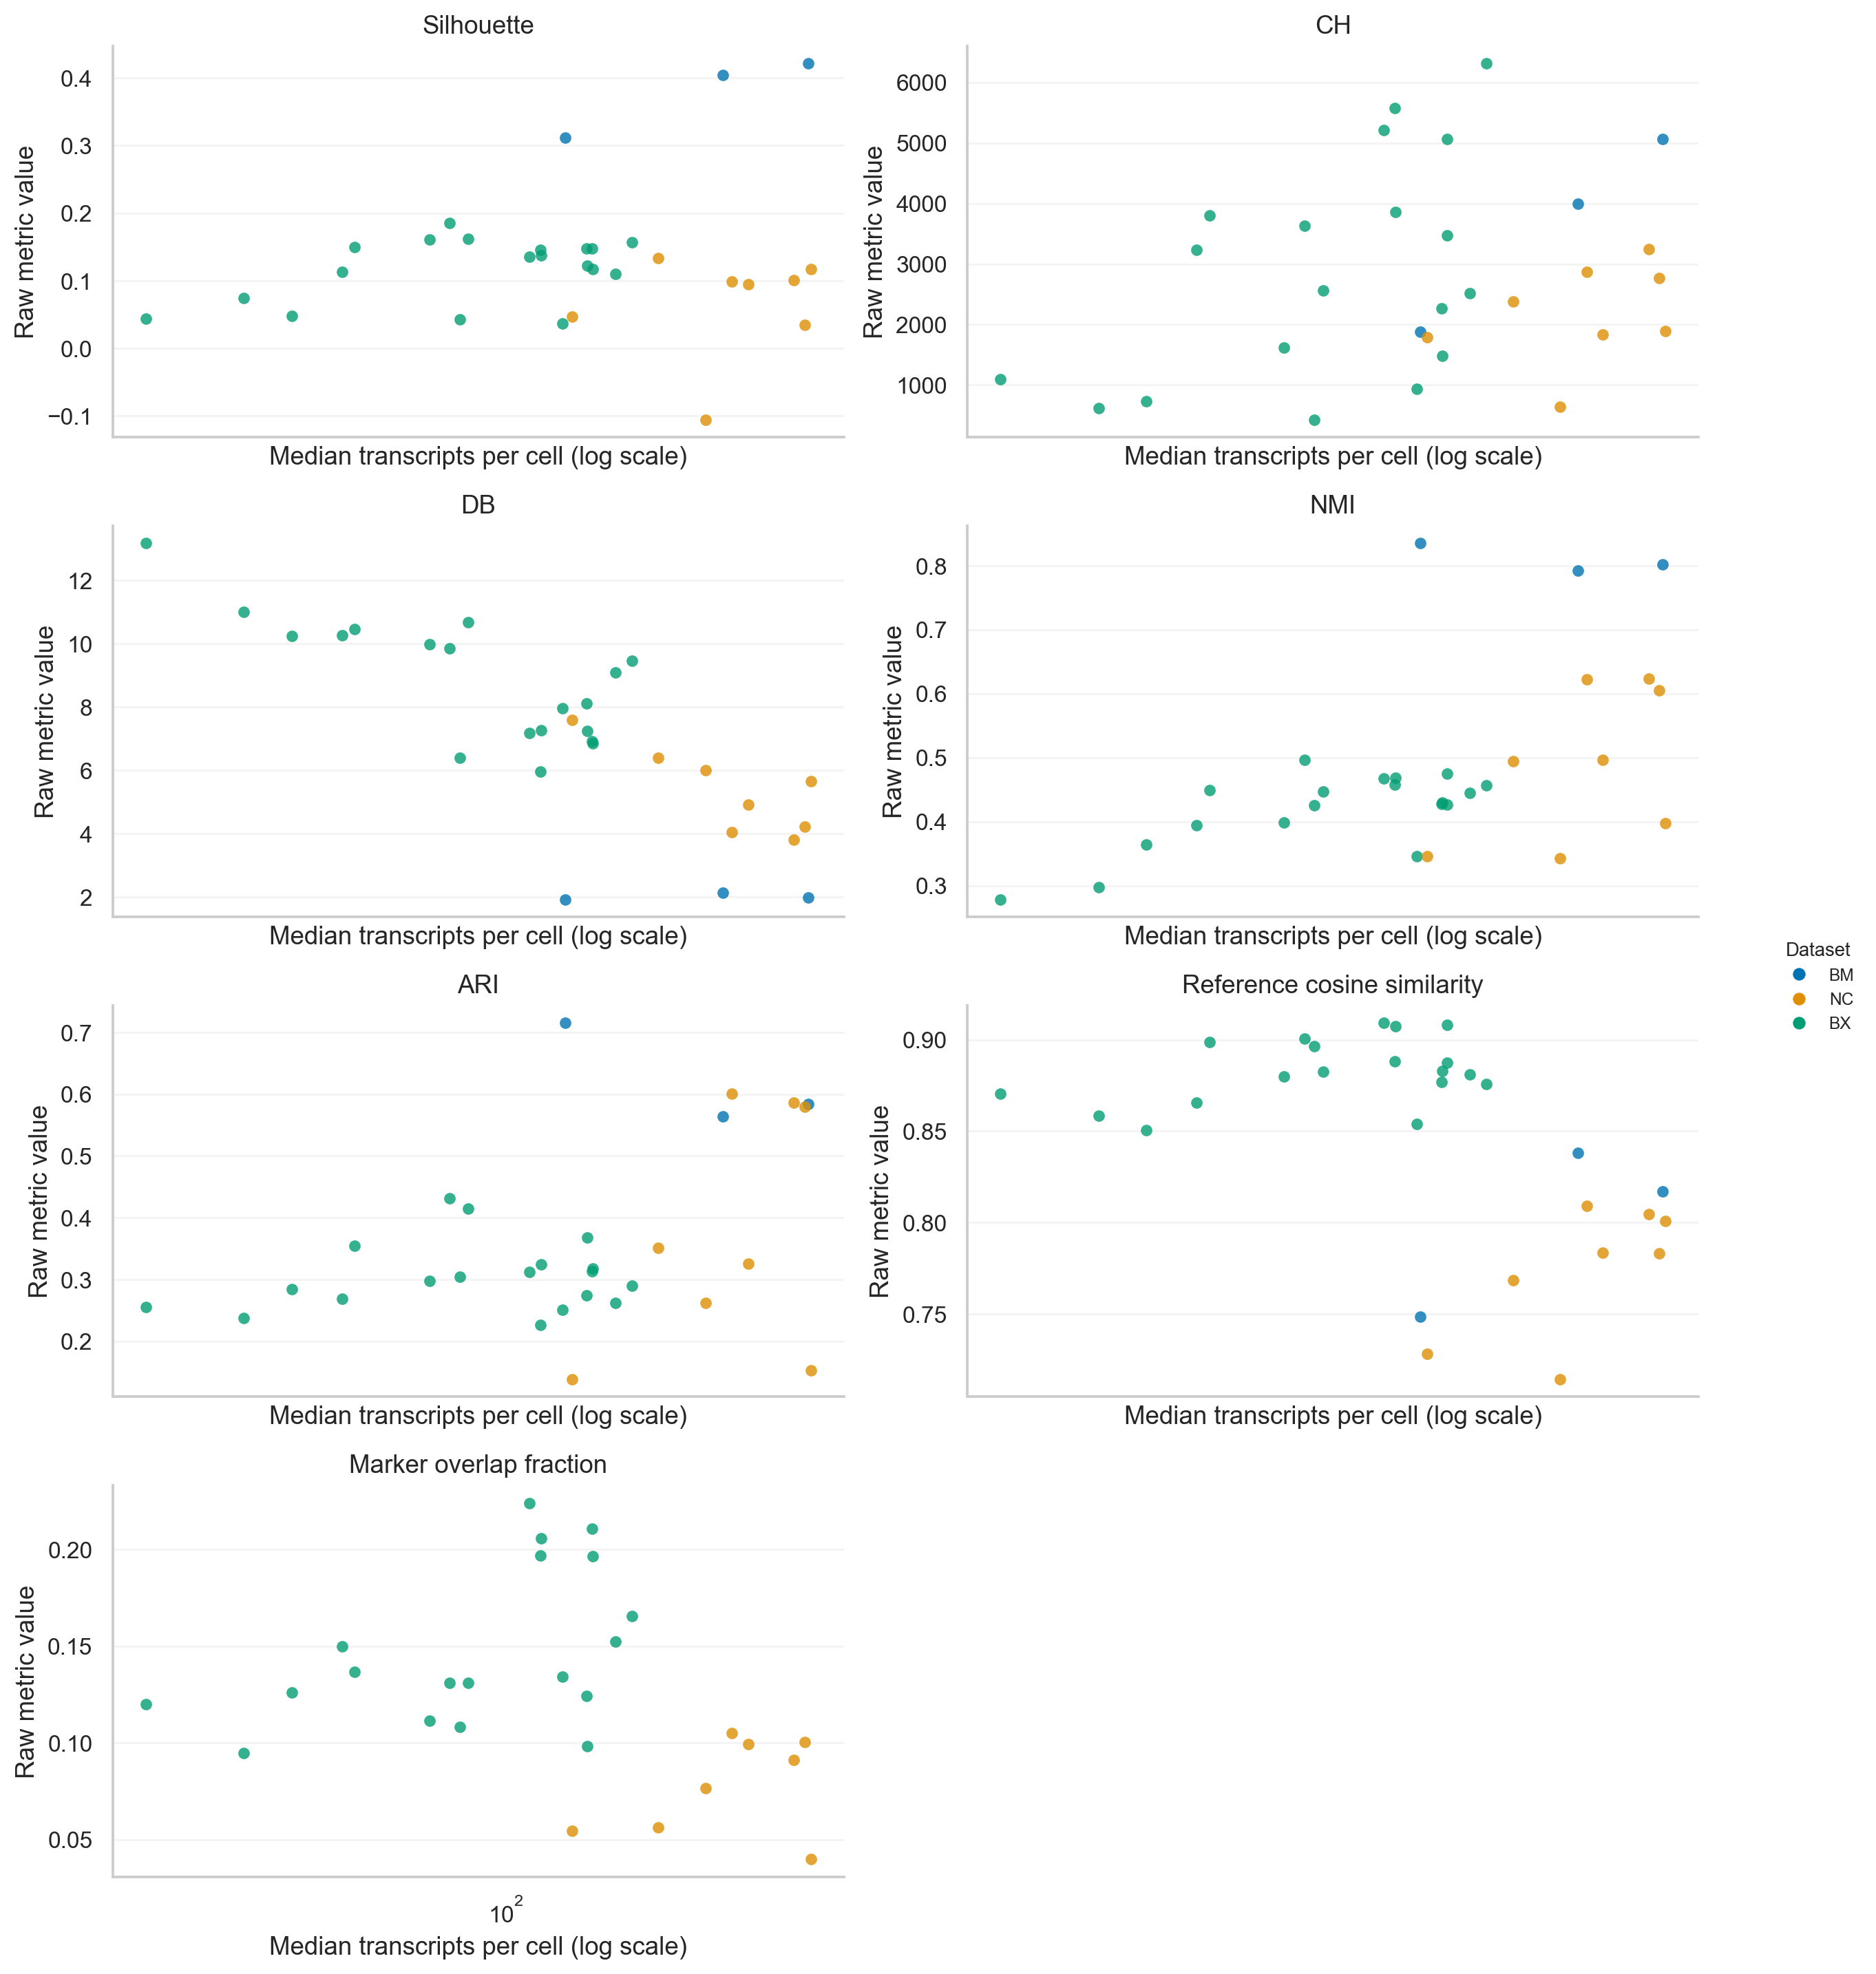

In [25]:
# Relate each slice's Raw metric to its median transcript count, colored by dataset.
transcript_counts_by_slice = (
    count_data.loc[count_data["method"].eq("ResolVI")]
    .assign(
        median_transcripts_per_cell=lambda frame: pd.to_numeric(
            frame["median_transcripts_per_cell"], errors="coerce"
        )
    )
    .groupby(["dataset", "slice"], observed=True)
    ["median_transcripts_per_cell"]
    .median()
    .reset_index()
)

metric_values_for_count_plot = pd.concat([
    non_tcell_original[["dataset", "slice", "method", "metric", "value"]],
    tcell_original[["dataset", "slice", "method", "metric", "value"]],
], ignore_index=True)
metrics_vs_transcript_count = metric_values_for_count_plot.loc[
    metric_values_for_count_plot["method"].eq("Raw")
].merge(
    transcript_counts_by_slice,
    on=["dataset", "slice"],
    how="inner",
)
metrics_vs_transcript_count = metrics_vs_transcript_count.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=["value", "median_transcripts_per_cell"])
metrics_vs_transcript_count = metrics_vs_transcript_count.loc[
    metrics_vs_transcript_count["median_transcripts_per_cell"] > 0
].copy()

metric_labels = [
    "Silhouette", "CH", "DB", "NMI", "ARI",
    "Reference cosine similarity", "Marker overlap fraction",
]
metric_labels = [
    metric for metric in metric_labels
    if metric in set(metrics_vs_transcript_count["metric"])
]
dataset_colors = dict(zip(
    DATASET_TITLES,
    sns.color_palette("colorblind", n_colors=len(DATASET_TITLES)),
))

ncols = 2
nrows = int(np.ceil(len(metric_labels) / ncols))
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(13.5, 3.3 * nrows),
    squeeze=False,
    sharex=True,
    dpi=220,
)
axes = axes.ravel()
for ax, metric in zip(axes, metric_labels):
    subset = metrics_vs_transcript_count.loc[
        metrics_vs_transcript_count["metric"].eq(metric)
    ]
    for dataset, group in subset.groupby("dataset", observed=True, sort=False):
        ax.scatter(
            group["median_transcripts_per_cell"], group["value"],
            color=dataset_colors.get(dataset, "#777777"),
            marker="o", s=30, alpha=0.8, linewidths=0,
        )
    ax.set_xscale("log")
    ax.set_title(metric, fontweight="bold")
    ax.set_ylabel("Raw metric value")
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)
    ax.margins(x=0.05)

for ax in axes[len(metric_labels):]:
    ax.remove()
for ax in axes[:len(metric_labels)]:
    ax.set_xlabel("Median transcripts per cell (log scale)")

dataset_handles = [
    plt.Line2D(
        [0], [0], marker="o", linestyle="", markersize=6,
        markerfacecolor=dataset_colors[dataset], markeredgecolor="none",
        label=DATASET_ALIASES.get(dataset, dataset),
    )
    for dataset in DATASET_TITLES
    if dataset in set(metrics_vs_transcript_count["dataset"])
]
fig.legend(
    handles=dataset_handles,
    title="Dataset",
    loc="center left", bbox_to_anchor=(0.87, 0.5),
    frameon=False, fontsize=8, title_fontsize=9,
)
fig.tight_layout(rect=(0, 0, 0.85, 1), h_pad=1.0, w_pad=0.8)
plt.show()


## Metrics versus total cells per slice

Same Raw-only metrics as above, plotted against the Raw metric run’s `n_cells` value for each slice. Dataset colors match the transcript-count plots.


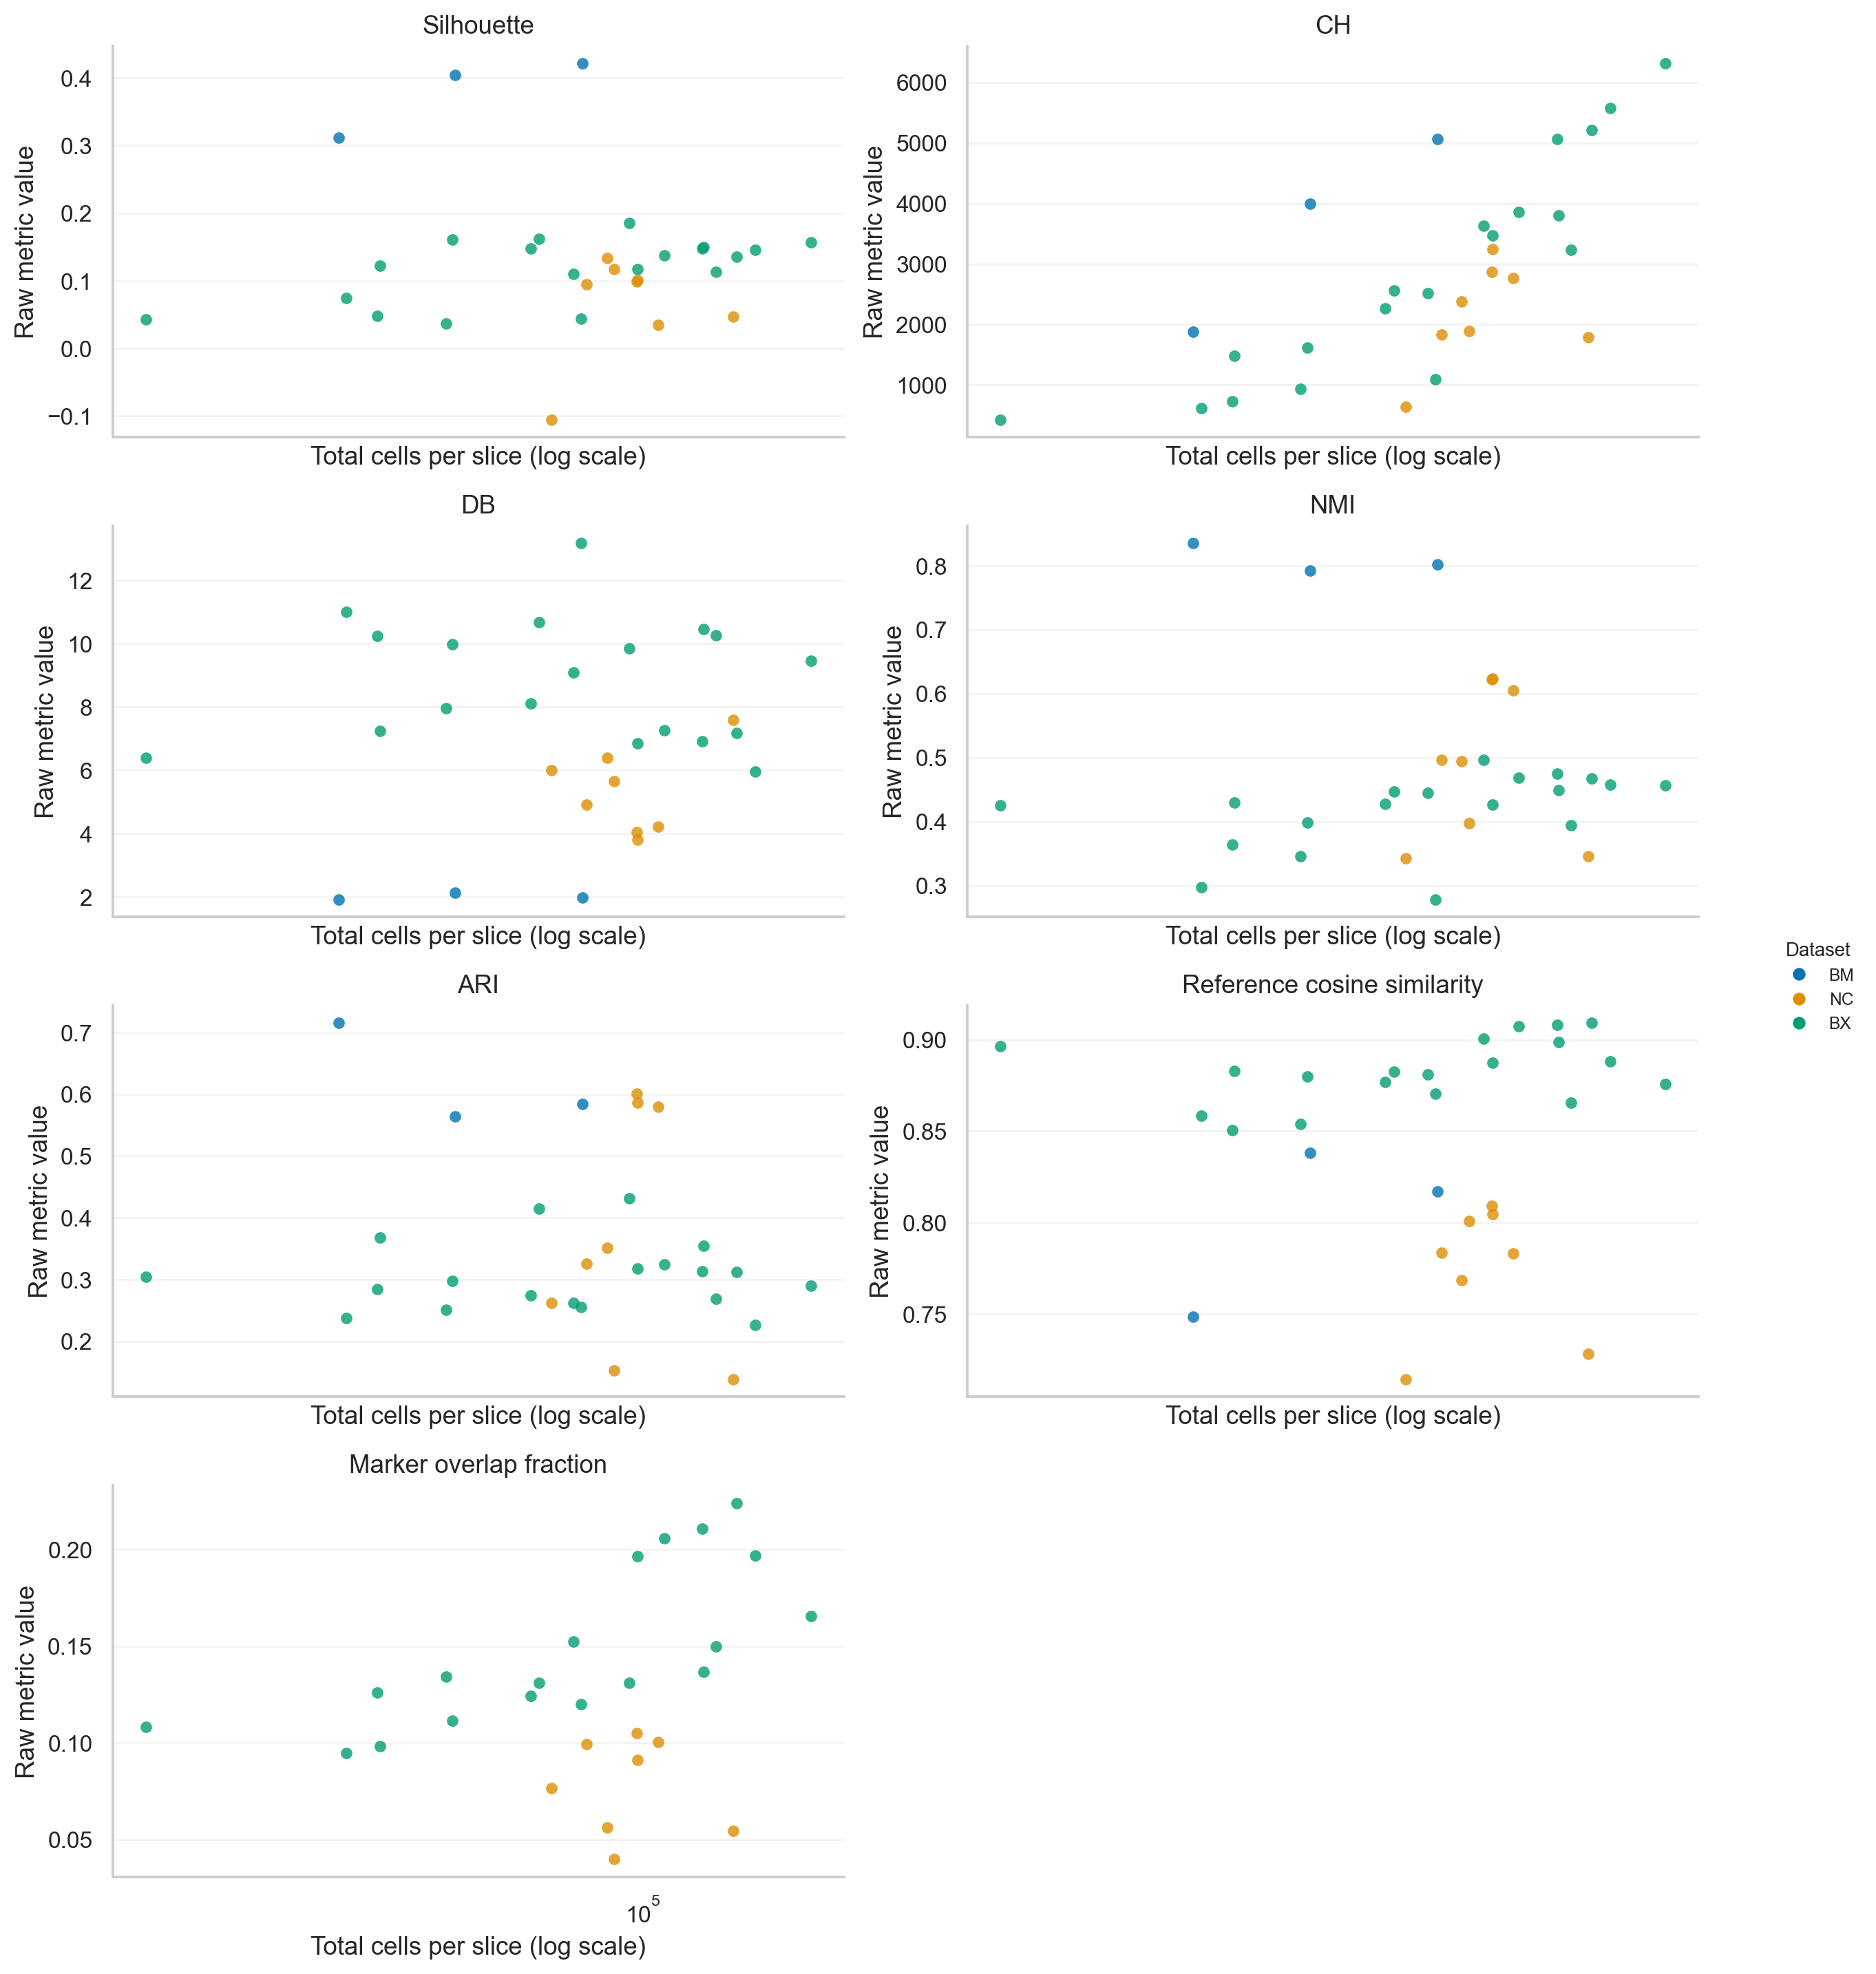

In [26]:
# Repeat the Raw-only metric panels using the slice cell count as x.
raw_slice_cell_counts = (
    non_tcell.loc[
        non_tcell["method"].eq("Raw"),
        ["dataset", "slice", "n_cells"],
    ]
    .assign(n_cells=lambda frame: pd.to_numeric(frame["n_cells"], errors="coerce"))
    .groupby(["dataset", "slice"], observed=True)["n_cells"]
    .max()
    .rename("slice_total_cells")
    .reset_index()
)
raw_metrics = metric_values_for_count_plot.loc[
    metric_values_for_count_plot["method"].eq("Raw")
]
metrics_vs_cell_count = raw_metrics.merge(
    raw_slice_cell_counts,
    on=["dataset", "slice"],
    how="inner",
).replace([np.inf, -np.inf], np.nan).dropna(subset=["value", "slice_total_cells"])
metrics_vs_cell_count = metrics_vs_cell_count.loc[
    metrics_vs_cell_count["slice_total_cells"] > 0
].copy()
cell_count_metric_labels = [
    metric for metric in metric_labels
    if metric in set(metrics_vs_cell_count["metric"])
]

ncols = 2
nrows = int(np.ceil(len(cell_count_metric_labels) / ncols))
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(13.5, 3.3 * nrows),
    squeeze=False,
    sharex=True,
    dpi=220,
)
axes = axes.ravel()
for ax, metric in zip(axes, cell_count_metric_labels):
    subset = metrics_vs_cell_count.loc[metrics_vs_cell_count["metric"].eq(metric)]
    for dataset, group in subset.groupby("dataset", observed=True, sort=False):
        ax.scatter(
            group["slice_total_cells"], group["value"],
            color=dataset_colors.get(dataset, "#777777"),
            marker="o", s=30, alpha=0.8, linewidths=0,
        )
    ax.set_xscale("log")
    ax.set_title(metric, fontweight="bold")
    ax.set_ylabel("Raw metric value")
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)
    ax.margins(x=0.05)

for ax in axes[len(cell_count_metric_labels):]:
    ax.remove()
for ax in axes[:len(cell_count_metric_labels)]:
    ax.set_xlabel("Total cells per slice (log scale)")

dataset_handles = [
    plt.Line2D(
        [0], [0], marker="o", linestyle="", markersize=6,
        markerfacecolor=dataset_colors[dataset], markeredgecolor="none",
        label=DATASET_ALIASES.get(dataset, dataset),
    )
    for dataset in DATASET_TITLES
    if dataset in set(metrics_vs_cell_count["dataset"])
]
fig.legend(
    handles=dataset_handles, title="Dataset",
    loc="center left", bbox_to_anchor=(0.87, 0.5),
    frameon=False, fontsize=8, title_fontsize=9,
)
fig.tight_layout(rect=(0, 0, 0.85, 1), h_pad=1.0, w_pad=0.8)
plt.show()


## Syndri: hard-zero metrics on QC-passing cells

Compare all-cell and QC-passing Syndri metrics from `syndri_zero_20261017_224620`. Both use hard zeroing and `SYNDRI_TARGET_FRACTIONS`. QC requires **≥10 counts and ≥5 expressed genes in the corrected matrix**. Aging brain uses milestone 87 predictions on the regenerated inputs.

These are non-T-cell separation metrics. Lines pair the same slice, with potentially different cells. QC exclusion counts and source paths are included below. Other methods retain their existing metric sources.


,dataset,available_files,selected_rows,source_root
0,brain_merfish,3,3,/work/magroup/skrieger/Syndri/data/datasets/br...
1,nsclc_cosmx,8,8,/work/magroup/skrieger/Syndri/data/datasets/ns...
2,breast_xenium,19,19,/work/magroup/skrieger/Syndri/data/datasets/br...


,dataset,slice,target_removed_fraction,n_cells_before_qc,n_cells_dropped_qc,source_csv
0,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.001,0.5,32528,84,/work/magroup/skrieger/Syndri/data/datasets/br...
1,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.002,0.5,50053,20,/work/magroup/skrieger/Syndri/data/datasets/br...
2,brain_merfish,st_integrated_slice-Zhuang-ABCA-4.003,0.5,79997,0,/work/magroup/skrieger/Syndri/data/datasets/br...
3,nsclc_cosmx,st_integrated_slice-Lung12,0.5,71304,444,/work/magroup/skrieger/Syndri/data/datasets/ns...
4,nsclc_cosmx,st_integrated_slice-Lung13,0.5,81236,180,/work/magroup/skrieger/Syndri/data/datasets/ns...
5,nsclc_cosmx,st_integrated_slice-Lung5_Rep1,0.5,98002,399,/work/magroup/skrieger/Syndri/data/datasets/ns...
6,nsclc_cosmx,st_integrated_slice-Lung5_Rep2,0.5,105800,5660,/work/magroup/skrieger/Syndri/data/datasets/ns...
7,nsclc_cosmx,st_integrated_slice-Lung5_Rep3,0.5,97809,424,/work/magroup/skrieger/Syndri/data/datasets/ns...
8,nsclc_cosmx,st_integrated_slice-Lung6,0.5,89975,561,/work/magroup/skrieger/Syndri/data/datasets/ns...
9,nsclc_cosmx,st_integrated_slice-Lung9_Rep1,0.5,87606,986,/work/magroup/skrieger/Syndri/data/datasets/ns...


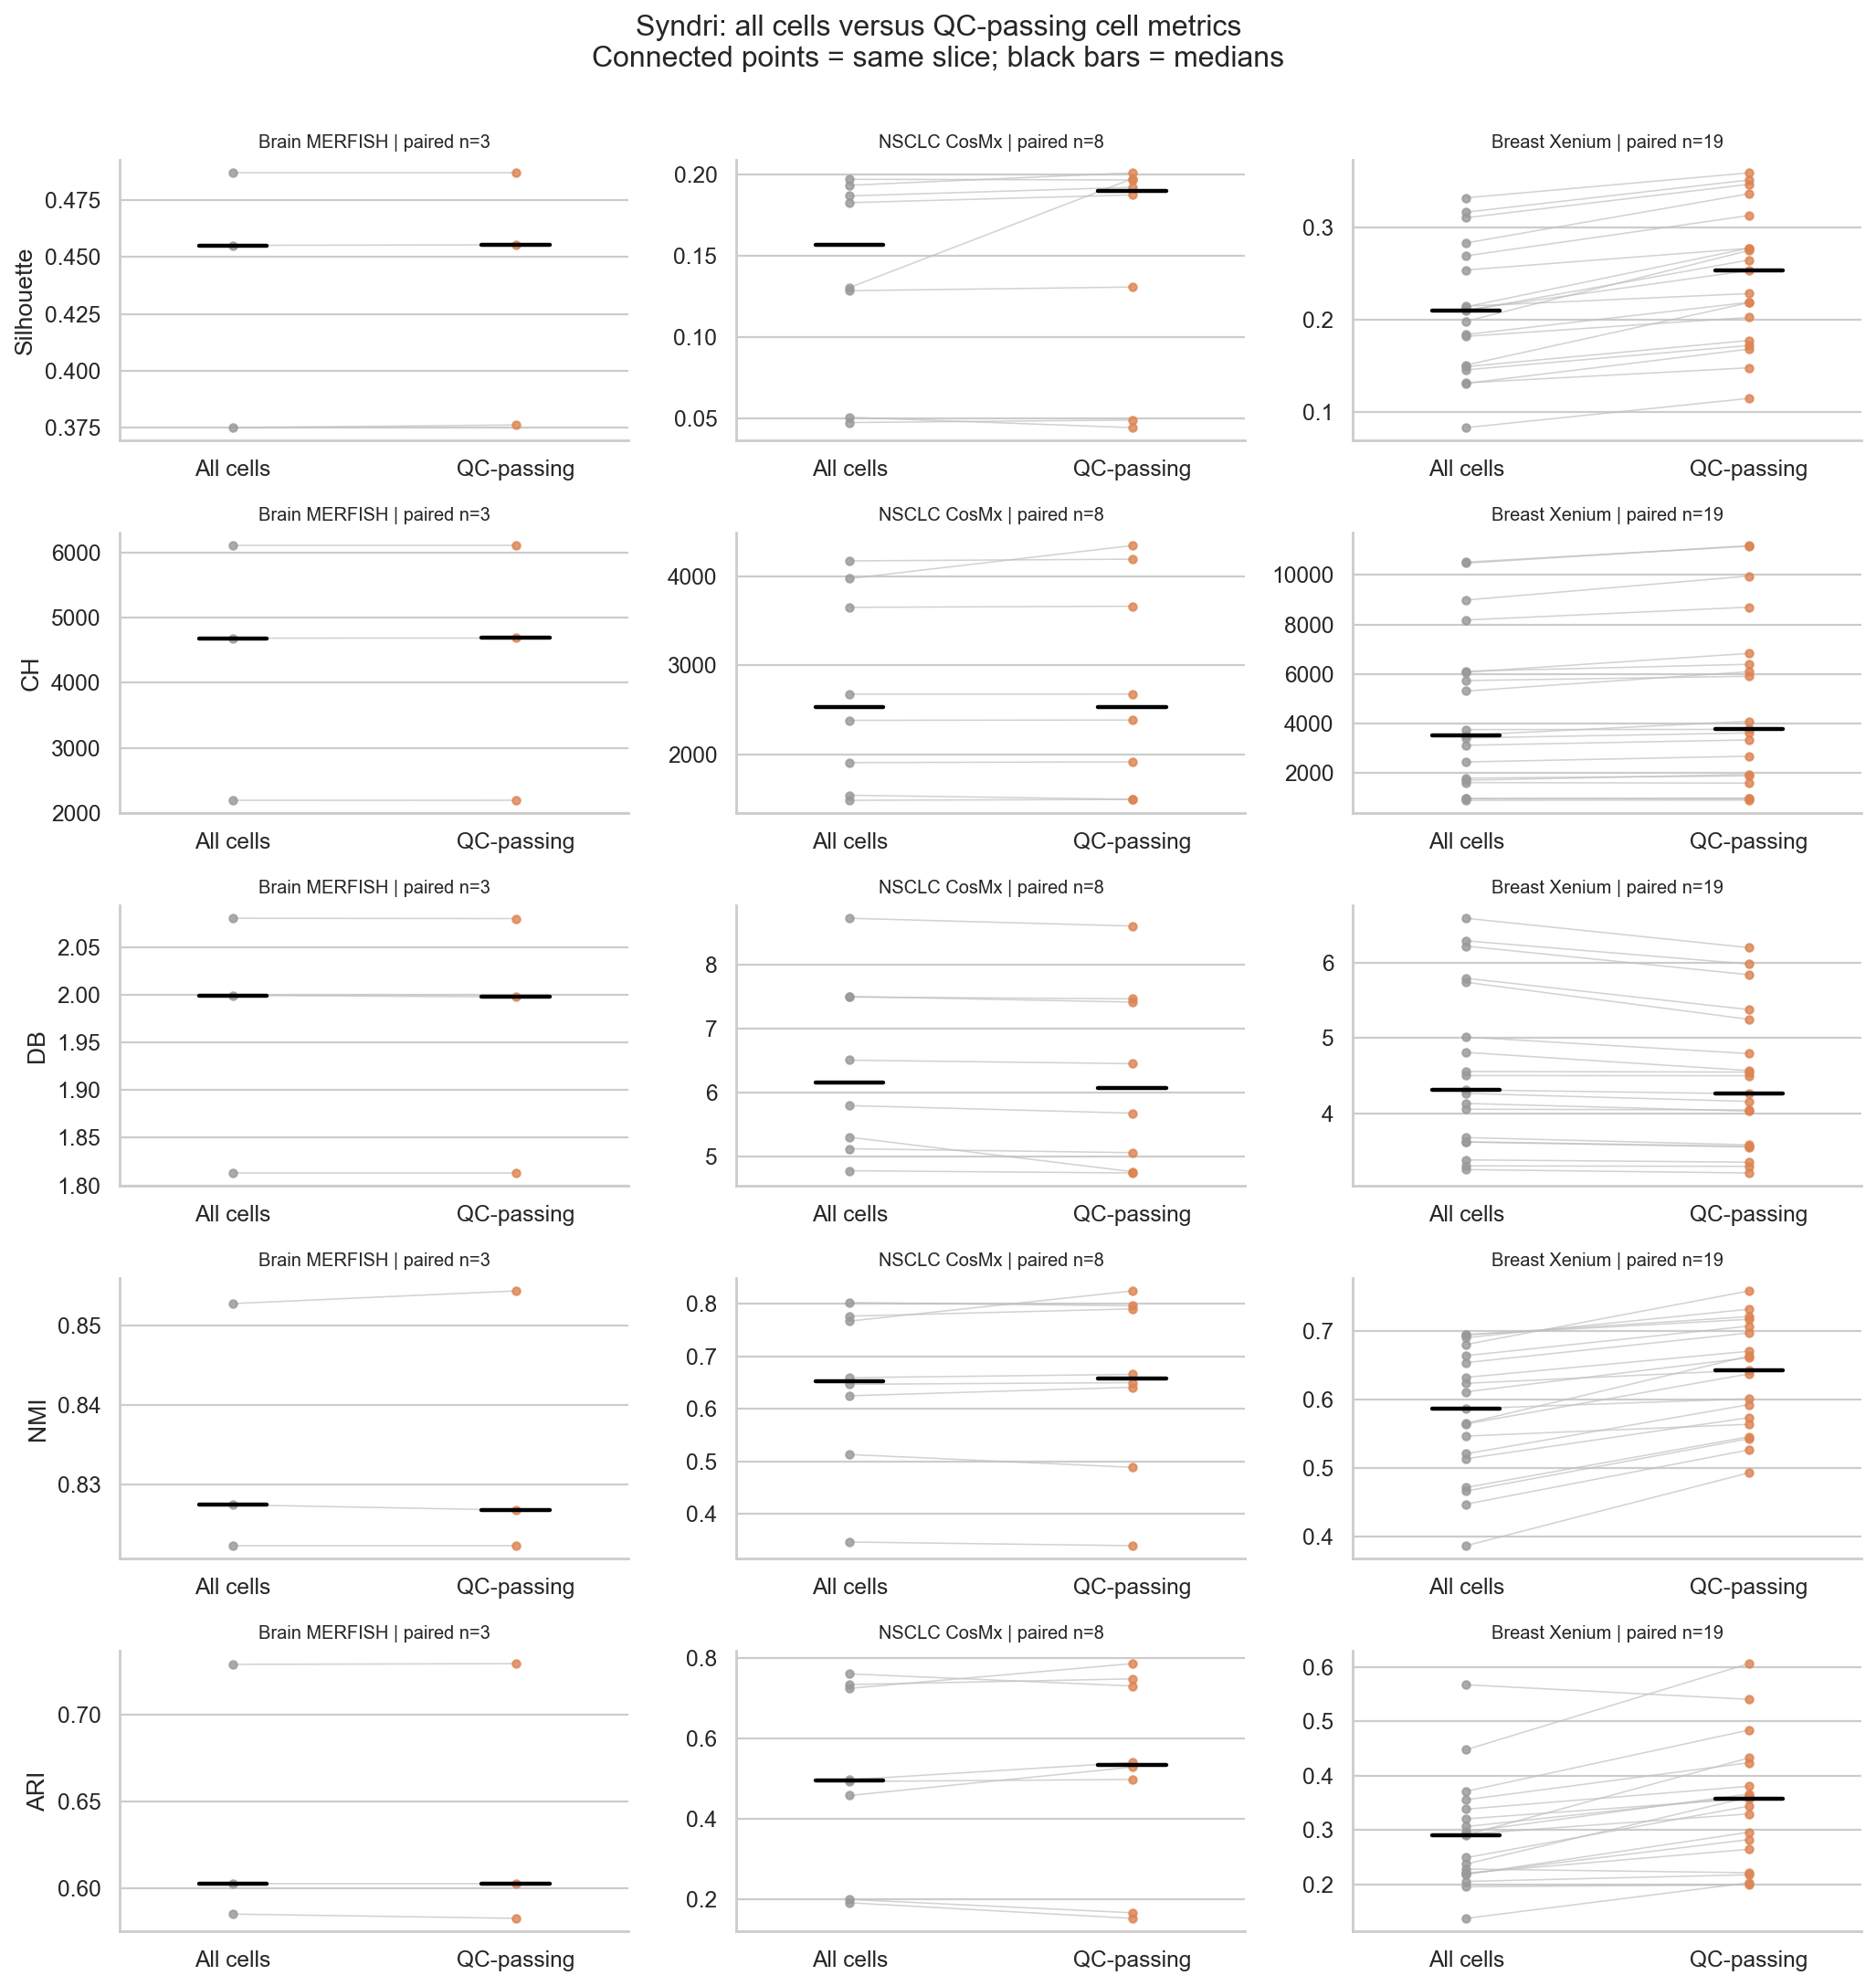

,dataset,metric,n_paired,mean_change,median_change
0,brain_merfish,Silhouette,3,0.000477,0.000257
1,nsclc_cosmx,Silhouette,8,0.010218,0.003495
2,breast_xenium,Silhouette,19,0.038681,0.034963
3,brain_merfish,CH,3,0.718100,0.974079
4,nsclc_cosmx,CH,8,47.484859,9.146010
5,breast_xenium,CH,19,335.333220,231.868823
6,brain_merfish,DB,3,-0.000654,-0.000327
7,nsclc_cosmx,DB,8,-0.130970,-0.074505
8,breast_xenium,DB,19,-0.159624,-0.096581
9,brain_merfish,NMI,3,0.000304,0.000000


In [27]:
SYNDRI_QC_RUN = f"{SYNDRI_METRICS_RUN}/qc10counts5genes/non_tcell"
syndri_qc_frames = []
qc_coverage = []
for dataset in DATASET_TITLES:
    qc_root = ROOT / dataset / "results/metrics" / SYNDRI_QC_RUN
    qc_files = sorted(qc_root.glob("*/non_tcell_metrics.csv"))
    n_selected = 0
    for path in qc_files:
        if not (path.parent / "complete.json").is_file():
            continue
        frame = pd.read_csv(path)
        frame["dataset"] = dataset
        frame["slice"] = path.parent.name
        frame["source_csv"] = str(path)
        frame = valid_rows(frame)
        frame = frame.loc[fixed_syndri_mask(frame, "case")].copy()
        if not frame.empty and not frame["cleaning_mode"].eq("zero").all():
            raise ValueError(f"Expected hard-zero QC metrics: {path}")
        n_selected += len(frame)
        syndri_qc_frames.append(frame)
    qc_coverage.append(dict(dataset=dataset, available_files=len(qc_files),
                            selected_rows=n_selected, source_root=str(qc_root)))
display(pd.DataFrame(qc_coverage))
if not syndri_qc_frames:
    raise FileNotFoundError("No Syndri QC metrics found")
syndri_qc = pd.concat(syndri_qc_frames, ignore_index=True)
if syndri_qc.empty:
    raise ValueError("No successful QC rows match the selected target fractions")
if syndri_qc.duplicated(["dataset", "slice"]).any():
    raise ValueError("Multiple QC rows per slice: resolve before plotting")
qc_audit_columns = ["dataset", "slice", "target_removed_fraction", "n_cells_before_qc",
                    "n_cells_dropped_qc", "source_csv"]
display(syndri_qc[[c for c in qc_audit_columns if c in syndri_qc]])

qc_long = syndri_qc.melt(id_vars=["dataset", "slice"],
    value_vars=list(NON_TCELL_METRICS), var_name="metric_key", value_name="value")
qc_long["metric"] = qc_long.metric_key.map({k:v[0] for k,v in NON_TCELL_METRICS.items()})
qc_long["cohort"] = "QC-passing Syndri"
existing_long = non_tcell_original.loc[non_tcell_original.method.eq(SYNDRI_LABEL),
                                      ["dataset", "slice", "metric", "value"]].copy()
existing_long["cohort"] = "All-cell Syndri"
syndri_qc_plot = pd.concat([existing_long, qc_long], ignore_index=True)
syndri_qc_plot["value"] = pd.to_numeric(syndri_qc_plot.value, errors="coerce")
syndri_qc_plot = syndri_qc_plot.loc[np.isfinite(syndri_qc_plot.value)]
qc_labels = ["All-cell Syndri", "QC-passing Syndri"]
qc_colors = ["#999999", COLORS[SYNDRI_LABEL]]
qc_metrics = [v[0] for v in NON_TCELL_METRICS.values()]
fig, axes = plt.subplots(len(qc_metrics), len(DATASET_TITLES),
                         figsize=(13, 2.7*len(qc_metrics)), squeeze=False, dpi=160)
qc_changes = []
for row, metric in enumerate(qc_metrics):
    for col, (dataset, title) in enumerate(DATASET_TITLES.items()):
        ax = axes[row, col]
        subset = syndri_qc_plot.loc[syndri_qc_plot.dataset.eq(dataset) & syndri_qc_plot.metric.eq(metric)]
        paired = subset.pivot(index="slice", columns="cohort", values="value").reindex(columns=qc_labels)
        for _, values in paired.dropna().iterrows():
            ax.plot([0,1], values.to_numpy(), color="0.75", linewidth=.7, alpha=.7, zorder=1)
        for position, label in enumerate(qc_labels):
            values = paired[label].dropna()
            ax.scatter(np.full(len(values), position), values, s=14, alpha=.8,
                       color=qc_colors[position], zorder=2)
            if len(values):
                ax.plot([position-.12,position+.12], [values.median()]*2,
                        color="black", linewidth=2, zorder=3)
        ax.set_xticks([0,1], ["All cells", "QC-passing"])
        ax.set_xlim(-.4,1.4)
        ax.set_title(f"{title} | paired n={len(paired.dropna())}", fontsize=9)
        ax.set_ylabel(metric if col==0 else "")
        ax.grid(axis="x", visible=False)
        diff=paired[qc_labels[1]]-paired[qc_labels[0]]
        qc_changes.append(dict(dataset=dataset, metric=metric, n_paired=int(diff.notna().sum()),
                               mean_change=diff.mean(), median_change=diff.median()))
fig.suptitle("Syndri: all cells versus QC-passing cell metrics\nConnected points = same slice; black bars = medians", y=1.005)
fig.tight_layout()
plt.show()
syndri_qc_changes = pd.DataFrame(qc_changes)
display(syndri_qc_changes)  # Signed QC − all cells; lower DB is better.


## All-cell-type reference cosine similarity

Each point is one slice. Within a slice, cosine similarities are averaged equally across annotated cell types with successful reference matches for every available method. Higher values indicate greater reference similarity. The y-axis spans 0.6–1.0. Gray hatched slots indicate unavailable methods; these results use all cells, without the Syndri-defined QC restriction.


/tmp/ipykernel_11778/1927789787.py:15: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=plot_frame, x="dataset_alias", y=value_col, hue="method",


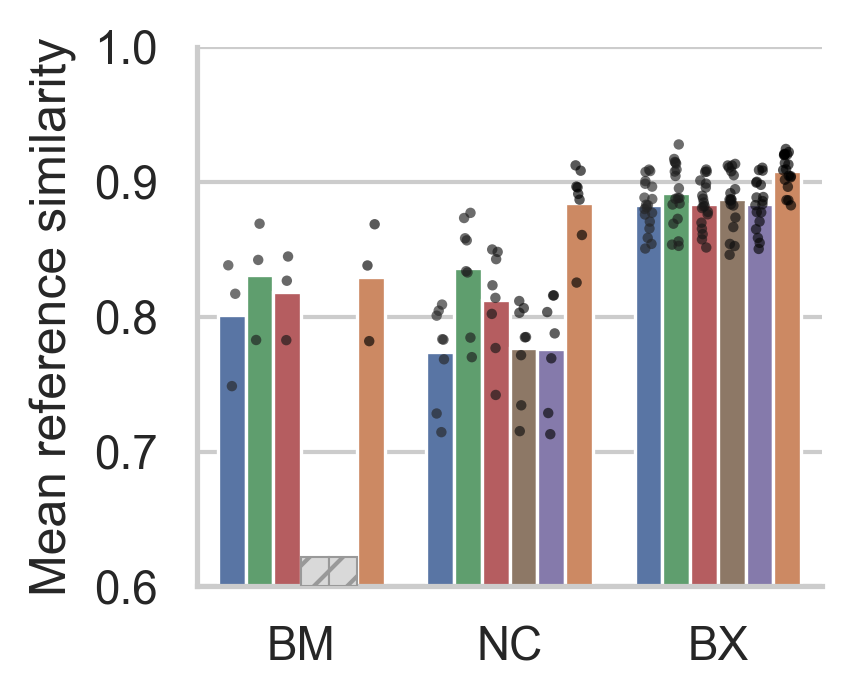

In [28]:
# Dedicated comparison of the new all-cell-type reference cosine results.
from matplotlib.patches import Patch, Rectangle

reference_dataset_order = list(DATASET_TITLES)
fig, ax = plt.subplots(figsize=(3, 3), dpi=300)
for ax, frame, value_col, methods, title, ylabel in [
    (ax, reference_cosine_original, "value", COUNT_METHOD_ORDER,
     "", "Mean reference similarity"),
]:
    plot_frame = frame.assign(dataset_alias=frame["dataset"].map(DATASET_ALIASES))
    aliases = [DATASET_ALIASES[d] for d in reference_dataset_order]
    sns.barplot(data=plot_frame, x="dataset_alias", y=value_col, hue="method",
                order=aliases, hue_order=methods, palette=COLORS,
                errorbar=None, linewidth=0.8, legend=False, ax=ax)
    sns.stripplot(data=plot_frame, x="dataset_alias", y=value_col, hue="method",
                  order=aliases, hue_order=methods, dodge=True, jitter=0.12,
                  color="black", size=2.5, alpha=0.65, legend=False, ax=ax)
    # Use axes-height placeholders so absence cannot be mistaken for a zero score.
    slot_width = 0.8 / len(methods)
    for x, dataset in enumerate(reference_dataset_order):
        present = set(frame.loc[frame["dataset"].eq(dataset), "method"])
        for j, method in enumerate(methods):
            if method not in present:
                left = x - 0.4 + j * slot_width
                ax.add_patch(Rectangle((left, 0), slot_width, 0.055,
                    transform=ax.get_xaxis_transform(), facecolor="0.85",
                    edgecolor="0.6", hatch="///", linewidth=0.5, zorder=3))
    ax.set(title=title, xlabel="", ylabel=ylabel)
    ax.grid(False, axis="x")
    ax.set_ylim(0.6, 1.0)

handles = [Patch(facecolor=COLORS[m], label=m) for m in COUNT_METHOD_ORDER]
handles.append(Patch(facecolor="0.85", edgecolor="0.6", hatch="///", label="Unavailable"))
# fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
#            bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=[0, 0.17, 1, 1])
# Optional publication export: fig.savefig("reference_cosine_all_cell_types.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / 'SuppFig2_refsim.svg',bbox_inches='tight')
plt.show()


### Reference cosine similarity by cell type and method

For each dataset, rows are annotated spatial cell types and columns are methods (Syndri last). Left: mean reference cosine similarity across slices. Right: mean paired difference from Raw, calculated within each slice before averaging. Cell types contribute only on slices with successful scores for every method available on that slice, matching the comparison above. Each slice has equal weight; aging-brain comparisons retain donor-specific references. Gray cells indicate missing results, not zero similarity. `reference_cosine_heatmap_counts` records the number of contributing slices per cell type and method.


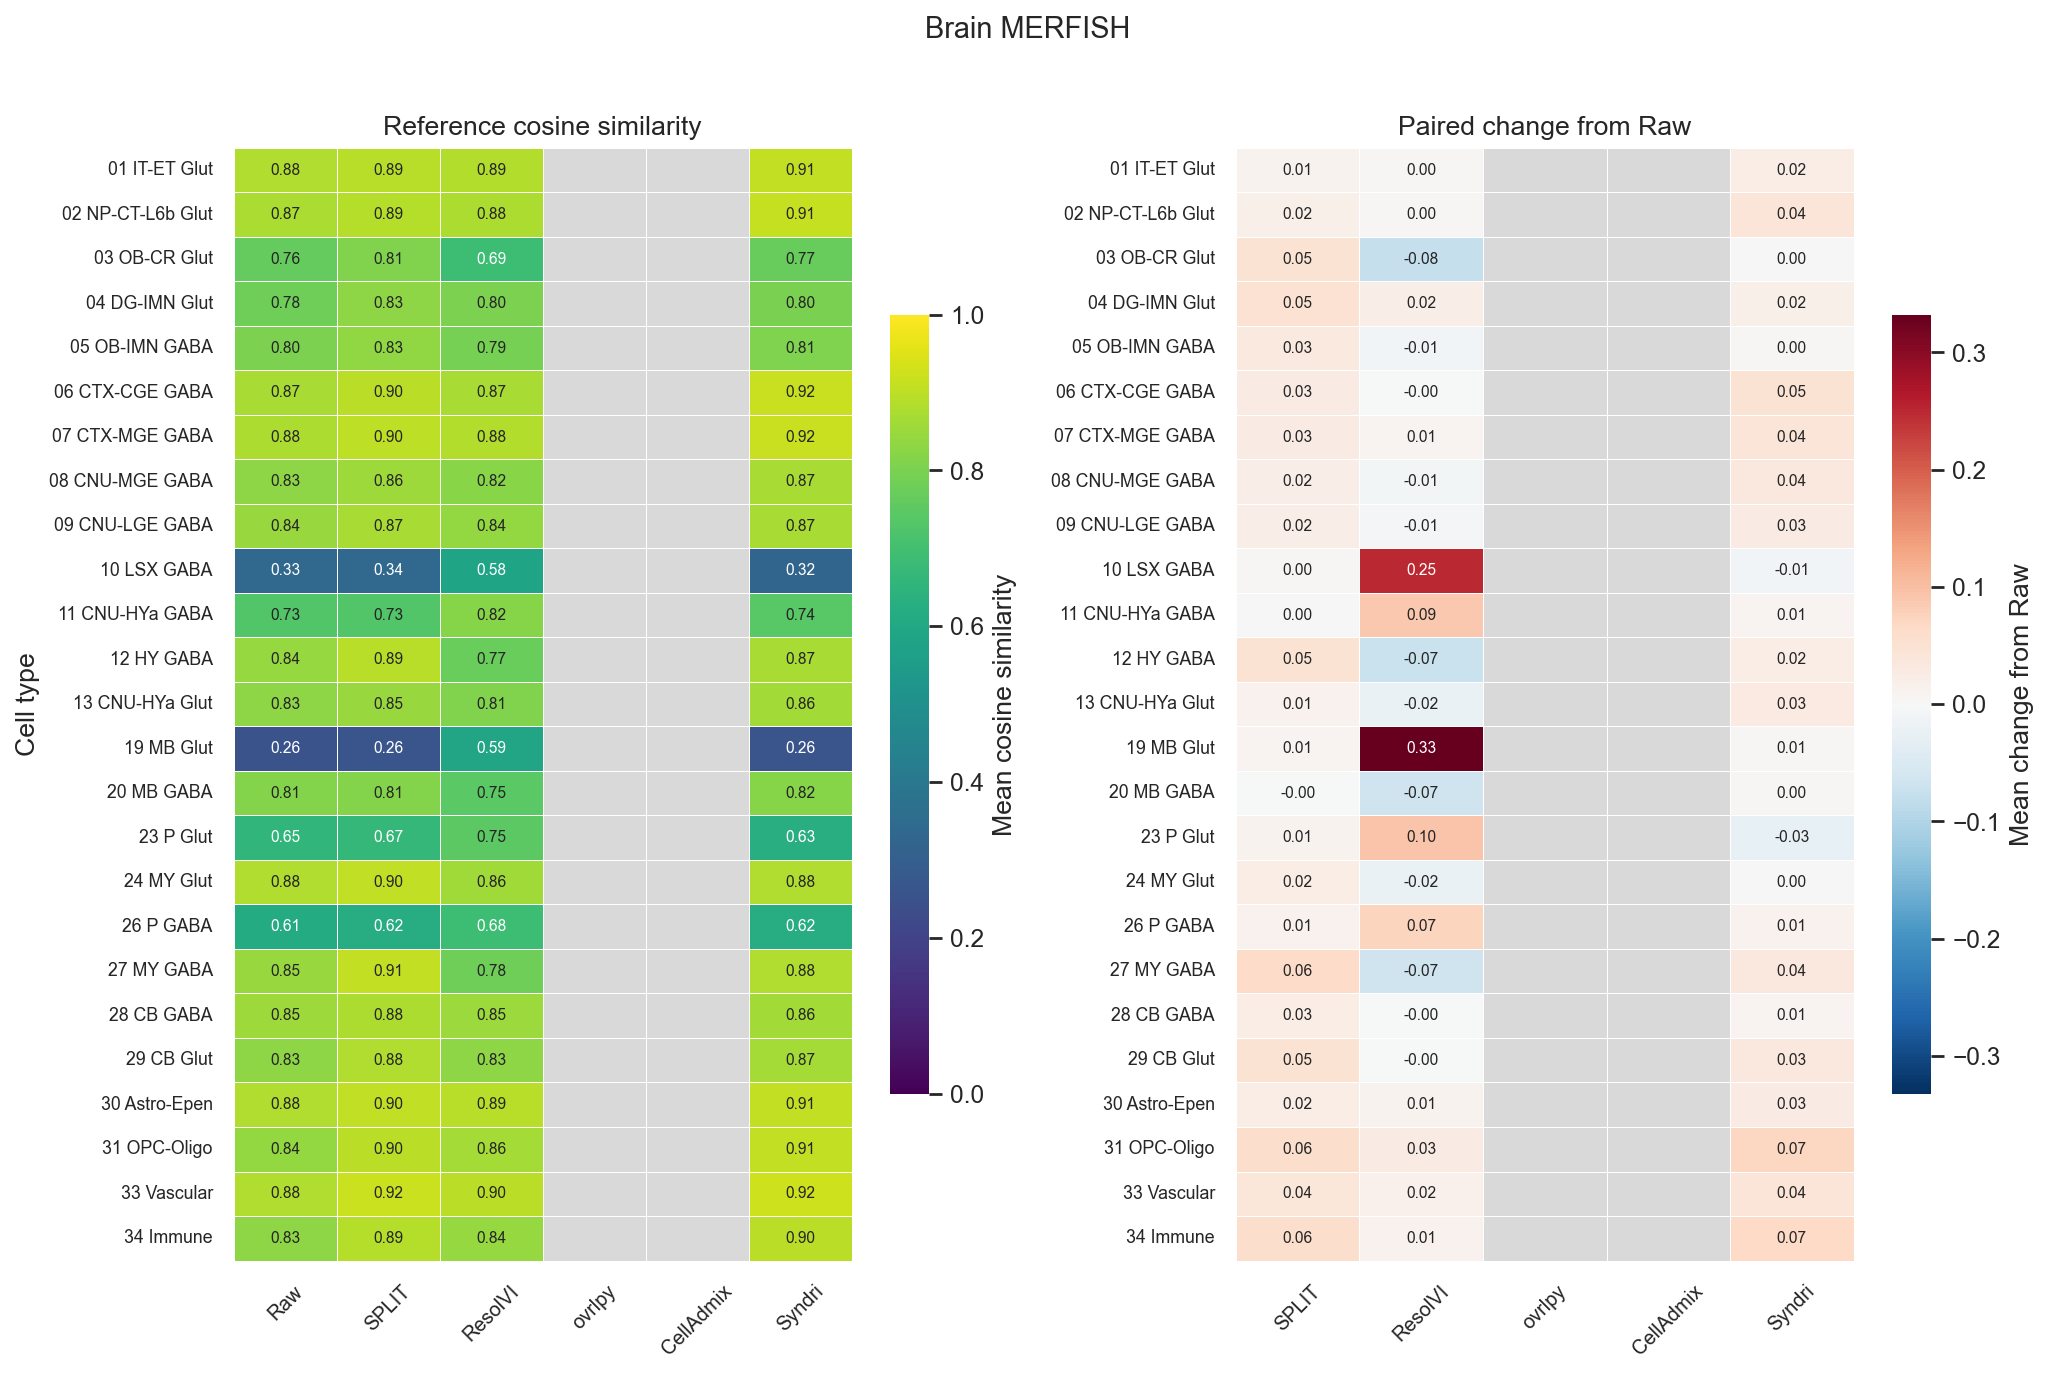

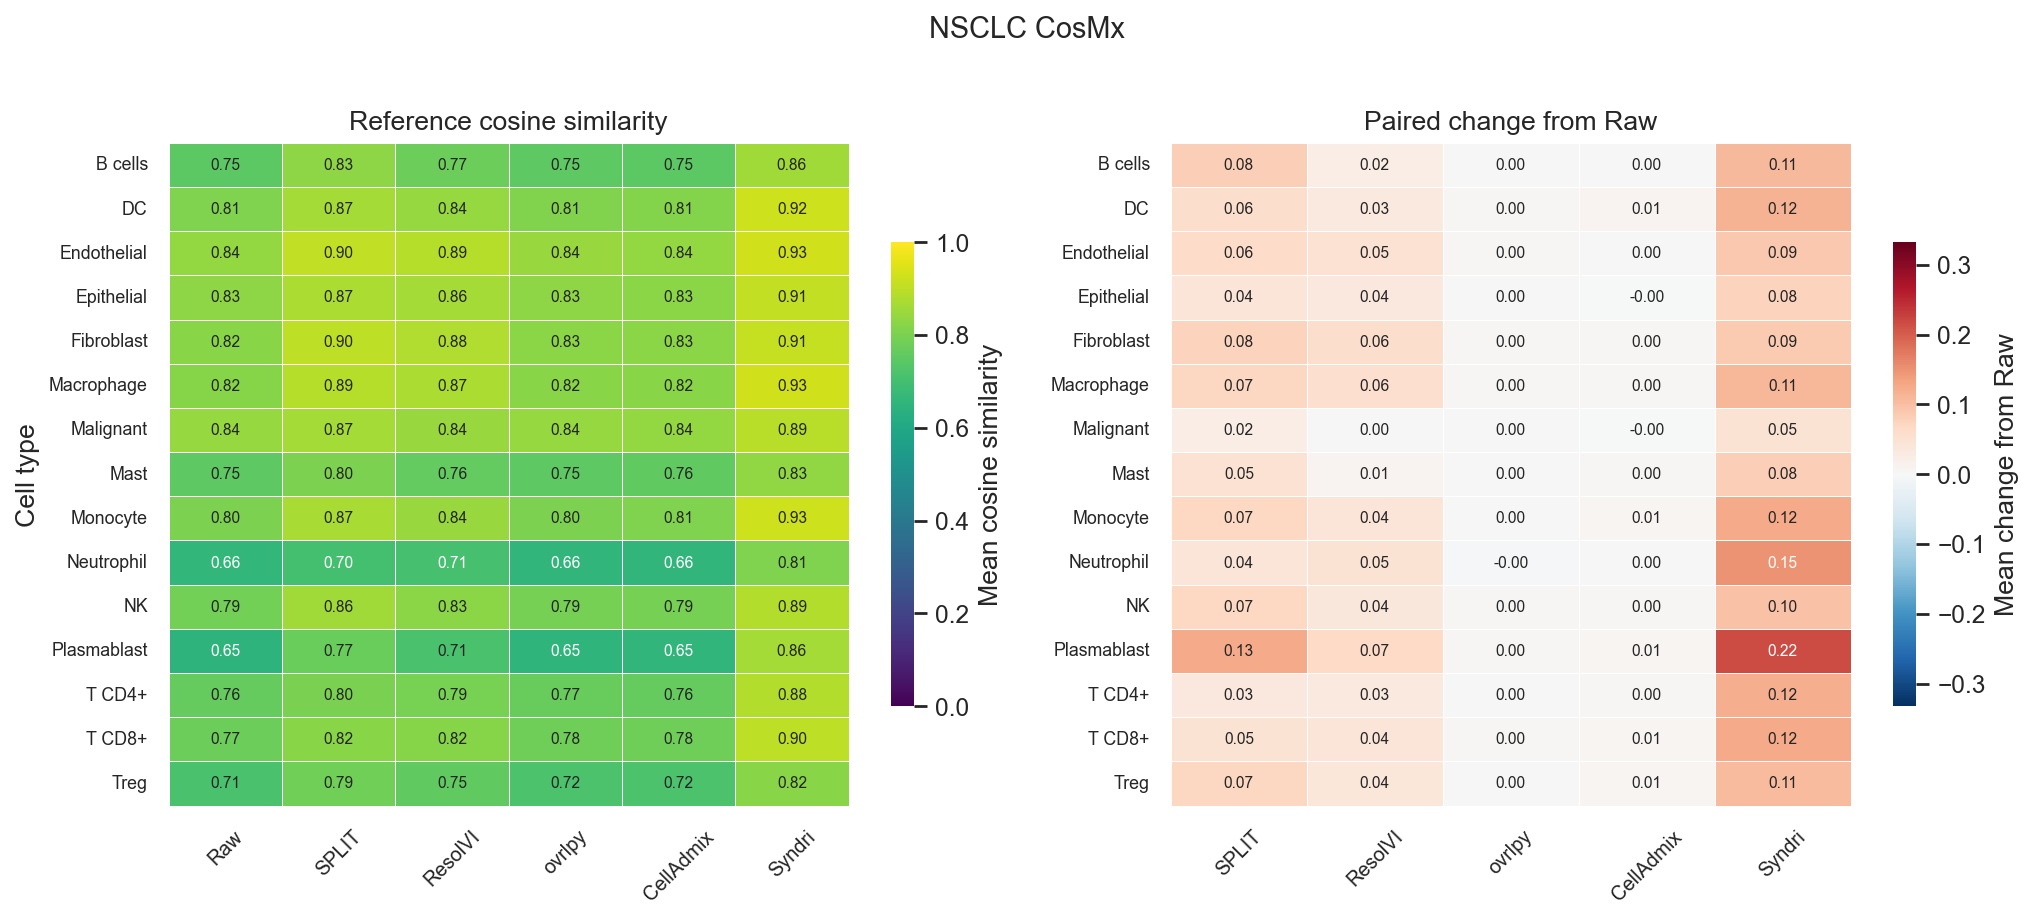

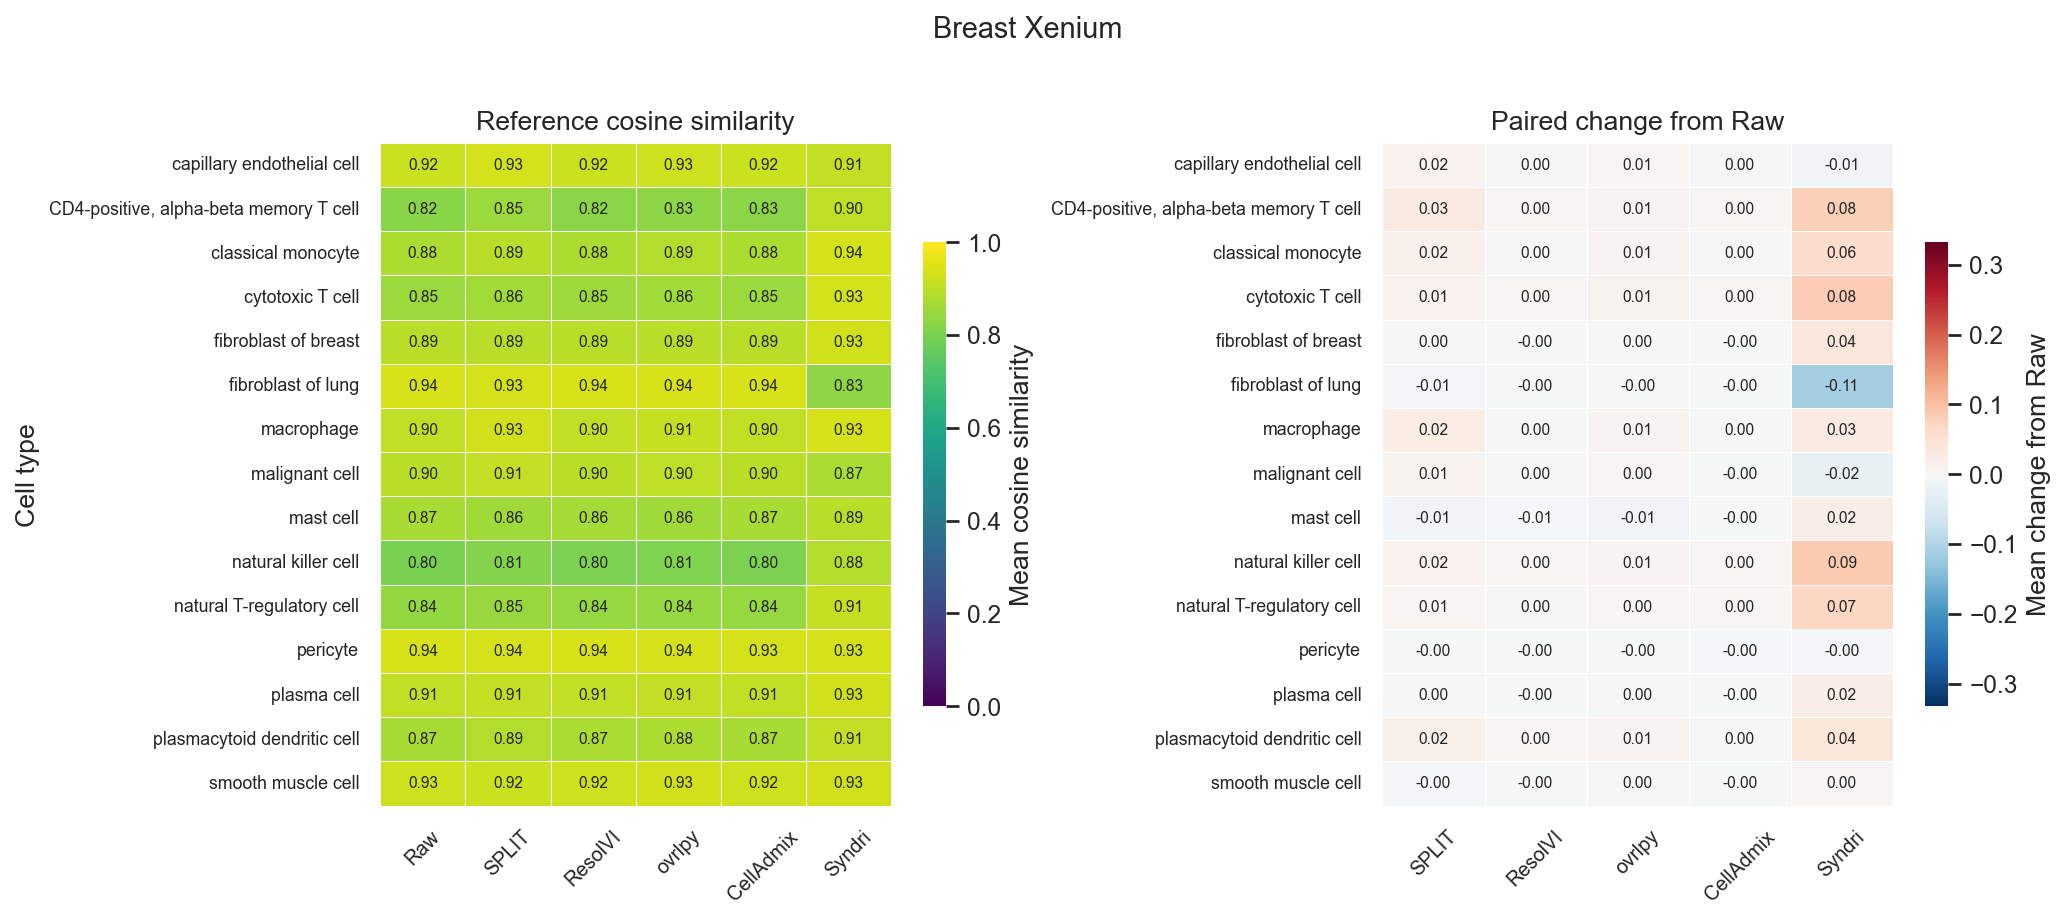

In [29]:
# Retain cell-type resolution instead of averaging cell types within each slice.
reference_type_tables = []
for (dataset, slice_id), group in cosine_all_rows.groupby(["dataset", "slice"], observed=True):
    methods = [m for m in COUNT_METHOD_ORDER if m in set(group["method"])]
    successful = group.loc[group["status"].eq("ok") & group["cosine_similarity"].notna()]
    values = successful.pivot(index=["spatial_cell_type", "reference_cell_type"],
                              columns="method", values="cosine_similarity")
    values = values.reindex(columns=methods).dropna(subset=methods)
    if values.empty or "Raw" not in values.columns:
        continue
    long = values.rename_axis(columns="method").reset_index().melt(
        id_vars=["spatial_cell_type", "reference_cell_type"],
        var_name="method", value_name="cosine_similarity")
    raw = values["Raw"].rename("raw_cosine_similarity").reset_index()
    long = long.merge(raw, on=["spatial_cell_type", "reference_cell_type"], validate="many_to_one")
    long["change_from_raw"] = long["cosine_similarity"] - long["raw_cosine_similarity"]
    reference_type_tables.append(long.assign(dataset=dataset, slice=slice_id))
reference_cosine_by_type = pd.concat(reference_type_tables, ignore_index=True)
# Preserve an inspectable coverage table alongside the plots.
reference_cosine_heatmap_counts = reference_cosine_by_type.groupby(
    ["dataset", "spatial_cell_type", "method"], observed=True)["slice"].nunique().rename("n_slices").reset_index()
reference_cosine_heatmap_means = reference_cosine_by_type.groupby(
    ["dataset", "spatial_cell_type", "method"], observed=True)[
        ["cosine_similarity", "change_from_raw"]].mean().reset_index()
change_limit = max(reference_cosine_heatmap_means["change_from_raw"].abs().max(), 0.001)
reference_heatmap_cmap = plt.get_cmap("viridis").copy()
reference_heatmap_cmap.set_bad("0.85")
reference_delta_cmap = plt.get_cmap("RdBu_r").copy()
reference_delta_cmap.set_bad("0.85")
for dataset, title in DATASET_TITLES.items():
    summary = reference_cosine_heatmap_means.loc[reference_cosine_heatmap_means["dataset"].eq(dataset)]
    if summary.empty:
        continue
    cell_types = sorted(summary["spatial_cell_type"].unique(), key=str.casefold)
    absolute = summary.pivot(index="spatial_cell_type", columns="method", values="cosine_similarity").reindex(
        index=cell_types, columns=COUNT_METHOD_ORDER)
    change = summary.pivot(index="spatial_cell_type", columns="method", values="change_from_raw").reindex(
        index=cell_types, columns=DELTA_PLOT_ORDER)
    fig, axes = plt.subplots(1, 2, figsize=(13, max(4, 0.29 * len(cell_types) + 1.5)), dpi=160)
    for ax, table, cmap, vmin, vmax, panel_title, colorbar_label in [
        (axes[0], absolute, reference_heatmap_cmap, 0, 1, "Reference cosine similarity", "Mean cosine similarity"),
        (axes[1], change, reference_delta_cmap, -change_limit, change_limit,
         "Paired change from Raw", "Mean change from Raw"),
    ]:
        ax.set_facecolor("0.85")
        sns.heatmap(table, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,
                    linewidths=0.3, linecolor="white", annot=True, fmt=".2f",
                    annot_kws={"fontsize":7}, cbar_kws={"label":colorbar_label, "shrink":0.7})
        ax.set(title=panel_title, xlabel="", ylabel="Cell type" if ax is axes[0] else "")
        ax.tick_params(axis="x", rotation=45, labelsize=9)
        ax.tick_params(axis="y", rotation=0, labelsize=8)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


## Cross-domain relative-rank summary

For each dataset and slice, rank methods separately on ARI, NMI, Silhouette, all-cell-type reference cosine similarity, and gene-wise variance Spearman concordance. Higher is better for all five measures. Convert ranks to  `q = 1 - (rank - 1) / (M - 1)`  within each slice, using average ranks for ties. Only slices with every applicable method present for all five measures enter the summary. Aging brain and brain MERFISH use Raw, SPLIT, ResolVI, and Syndri; ovrlpy and CellAdmix are excluded there. CosMx and Xenium require all six methods.

Average slice scores within each dataset first. Separability is the equal mean of ARI, NMI, and Silhouette; Reference and Variance each use their single metric; Overall is the equal mean of the three domains. The displayed heatmap averages dataset-level scores equally, so datasets with more slices do not dominate. Dataset-level scores and complete-slice counts remain available below. Run `context_analysis/VariancePreservation.ipynb` through its export cell before running this section.
The second summary uses a dot plot grouped by dataset, with Sep., Ref., Var., and Overall within each dataset. Dot color and the centered value encode the relative-rank score; gray × marks unavailable method/dataset combinations.


Complete-case slice coverage:


,dataset,methods_required,n_complete_slices
0,brain_merfish,"Raw, SPLIT, ResolVI, Syndri",3
1,nsclc_cosmx,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",7
2,breast_xenium,"Raw, SPLIT, ResolVI, ovrlpy, CellAdmix, Syndri",18


Dataset-level relative-rank scores:


,dataset,method,Separability,Reference,Variance,Overall
0,brain_merfish,Raw,0.407407,0.000000,0.333333,0.246914
1,brain_merfish,ResolVI,0.333333,0.444444,0.000000,0.259259
2,brain_merfish,SPLIT,0.481481,1.000000,0.666667,0.716049
3,brain_merfish,Syndri,0.777778,0.555556,1.000000,0.777778
4,breast_xenium,CellAdmix,0.588889,0.300000,0.322222,0.403704
5,breast_xenium,Raw,0.374074,0.200000,0.300000,0.291358
6,breast_xenium,ResolVI,0.603704,0.266667,0.000000,0.290123
7,breast_xenium,SPLIT,0.525926,0.711111,0.677778,0.638272
8,breast_xenium,Syndri,0.740741,0.988889,1.000000,0.909877
9,breast_xenium,ovrlpy,0.166667,0.533333,0.700000,0.466667


Across-dataset macro-average relative-rank scores:


,Separability,Reference,Variance,Overall
method,,,,
Raw,0.333510,0.076190,0.439683,0.283128
SPLIT,0.523104,0.827513,0.610053,0.653557
ResolVI,0.591711,0.446561,0.009524,0.349265
ovrlpy,0.111905,0.409524,0.578571,0.366667
CellAdmix,0.551587,0.292857,0.332540,0.392328
Syndri,0.776014,0.848148,1.000000,0.874721


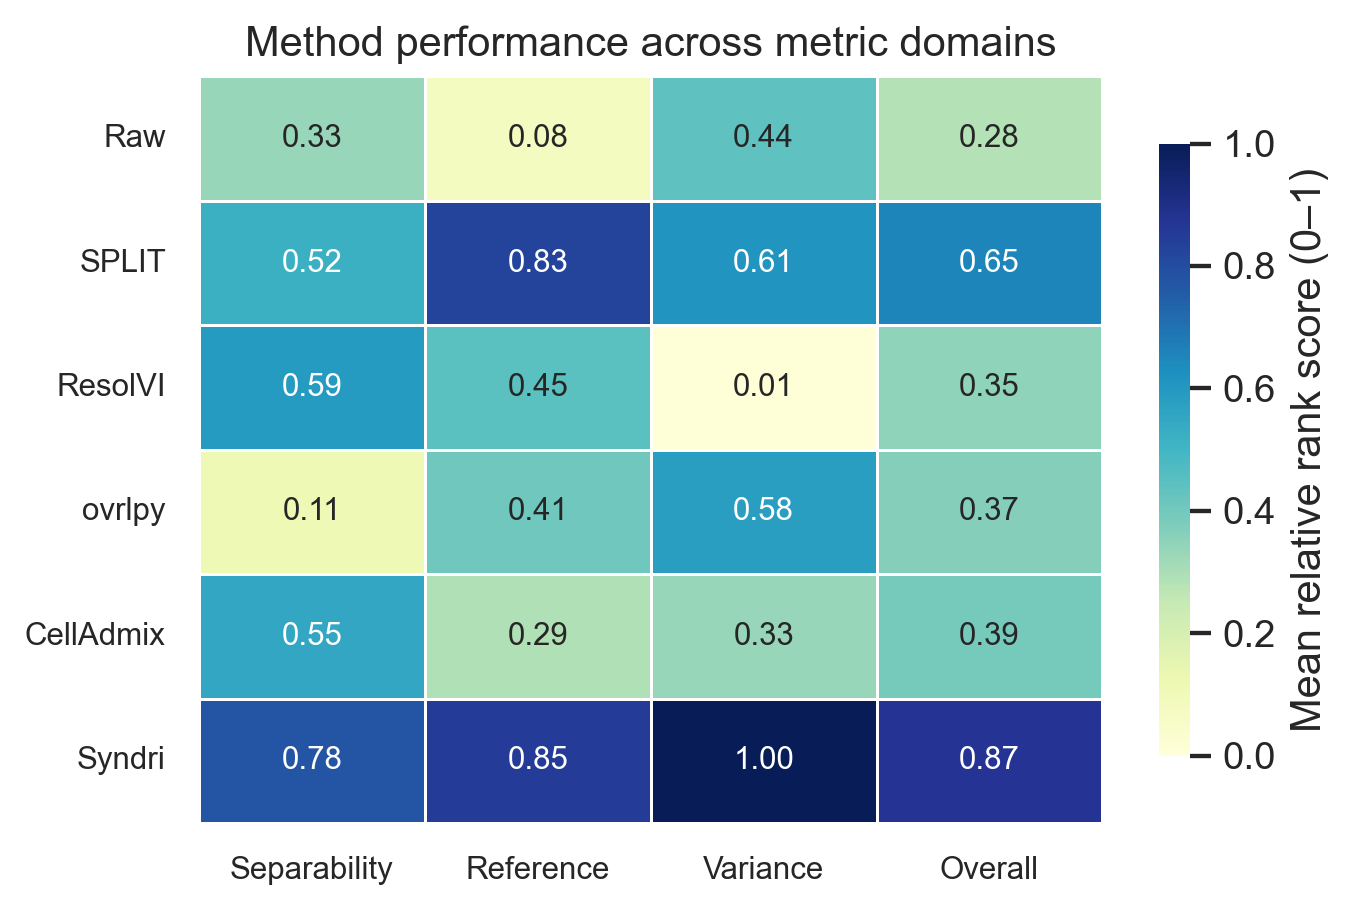

Dataset-specific relative-rank scores by domain:


brain_merfish                                nsclc_cosmx            \
           Separability Reference  Variance   Overall Separability Reference   
method                                                                         
Raw            0.407407  0.000000  0.333333  0.246914     0.219048  0.028571   
SPLIT          0.481481  1.000000  0.666667  0.716049     0.561905  0.771429   
ResolVI        0.333333  0.444444  0.000000  0.259259     0.838095  0.628571   
ovrlpy              NaN       NaN       NaN       NaN     0.057143  0.285714   
CellAdmix           NaN       NaN       NaN       NaN     0.514286  0.285714   
Syndri         0.777778  0.555556  1.000000  0.777778     0.809524  1.000000   

                              breast_xenium                                
           Variance   Overall  Separability Reference  Variance   Overall  
method                                                                     
Raw        0.685714  0.311111      0.374074  0.200000  0.300000  0.291358  
SPLIT      0.485714  0.606349      0.525926  0.711111  0.677778  0.638272  
ResolVI    0.028571  0.498413      0.603704  0.266667  0.000000  0.290123  
ovrlpy     0.457143  0.266667      0.166667  0.533333  0.700000  0.466667  
CellAdmix  0.342857  0.380952      0.588889  0.300000  0.322222  0.403704  
Syndri     1.000000  0.936508      0.740741  0.988889  1.000000  0.909877

In [30]:
# Rank methods within each slice, then summarize by dataset and domain.
VARIANCE_CONCORDANCE_PATH = Path('/home/jwinchel/Syndri/context_analysis/results/variance_preservation_slice_concordance.csv')
if not VARIANCE_CONCORDANCE_PATH.is_file():
    raise FileNotFoundError(
        f'Missing {VARIANCE_CONCORDANCE_PATH}; run VariancePreservation.ipynb through its export cell first.'
    )
variance_comparisons = pd.read_csv(VARIANCE_CONCORDANCE_PATH, low_memory=False)
required_variance_columns = {'dataset', 'slice', 'cell_type', 'method', 'spearman_rho', 'status'}
missing_variance_columns = required_variance_columns - set(variance_comparisons.columns)
if missing_variance_columns:
    raise KeyError(f'Variance concordance export is missing columns: {sorted(missing_variance_columns)}')

# Match VariancePreservation.ipynb: one slice-level value is the median rho
# across eligible cell types, using successful comparisons only.
variance_slice_scores = (
    variance_comparisons.loc[
        variance_comparisons['status'].eq('ok')
        & variance_comparisons['spearman_rho'].notna()
    ]
    .groupby(['dataset', 'slice', 'method'], observed=True)['spearman_rho']
    .median().rename('value').reset_index()
    .assign(metric='Variance')
)
cluster_metric_names = ['ARI', 'NMI', 'Silhouette']
cluster_slice_scores = non_tcell_original.loc[
    non_tcell_original['metric'].isin(cluster_metric_names),
    ['dataset', 'slice', 'method', 'metric', 'value'],
].copy()
# Recompute slice-level reference means using only the methods applicable to
# that dataset, so MERFISH comparisons exclude ovrlpy and CellAdmix entirely.
rank_reference_rows = []
merfish_datasets = {'agingbrain_merfish', 'brain_merfish'}
rank_method_order = ['Raw', 'SPLIT', 'ResolVI', 'ovrlpy', 'CellAdmix', 'Syndri']
for (dataset, slice_id), group in cosine_all_rows.groupby(
    ['dataset', 'slice'], observed=True
):
    applicable_methods = (
        ['Raw', 'SPLIT', 'ResolVI', 'Syndri']
        if dataset in merfish_datasets
        else rank_method_order
    )
    successful = group.loc[
        group['status'].eq('ok') & group['cosine_similarity'].notna()
    ]
    values = successful.pivot(
        index=['spatial_cell_type', 'reference_cell_type'],
        columns='method', values='cosine_similarity',
    ).reindex(columns=applicable_methods)
    matched = values.dropna(subset=applicable_methods)
    for method in applicable_methods:
        if not matched.empty:
            rank_reference_rows.append({
                'dataset': dataset, 'slice': slice_id, 'method': method,
                'metric': 'Reference', 'value': matched[method].mean(),
            })
reference_slice_scores = pd.DataFrame(rank_reference_rows)
rank_input = pd.concat(
    [cluster_slice_scores, reference_slice_scores, variance_slice_scores],
    ignore_index=True,
)
rank_input['value'] = pd.to_numeric(rank_input['value'], errors='coerce')
rank_input = rank_input.replace([np.inf, -np.inf], np.nan).dropna(subset=['value'])

rank_metrics = [*cluster_metric_names, 'Reference', 'Variance']
rank_rows = []
rank_coverage_rows = []
for dataset in DATASET_TITLES:
    applicable_methods = (
        ['Raw', 'SPLIT', 'ResolVI', 'Syndri']
        if dataset in merfish_datasets
        else rank_method_order
    )
    dataset_values = rank_input.loc[
        rank_input['dataset'].eq(dataset)
        & rank_input['method'].isin(applicable_methods)
        & rank_input['metric'].isin(rank_metrics)
    ]
    metric_tables = {}
    complete_slices = None
    for metric in rank_metrics:
        table = dataset_values.loc[dataset_values['metric'].eq(metric)].pivot_table(
            index='slice', columns='method', values='value', aggfunc='mean'
        ).reindex(columns=applicable_methods)
        metric_tables[metric] = table
        present = table.index[table.notna().all(axis=1)]
        complete_slices = present if complete_slices is None else complete_slices.intersection(present)
    complete_slices = pd.Index([]) if complete_slices is None else complete_slices
    rank_coverage_rows.append({
        'dataset': dataset,
        'methods_required': ', '.join(applicable_methods),
        'n_complete_slices': len(complete_slices),
    })
    if len(applicable_methods) < 2 or complete_slices.empty:
        continue
    for metric, table in metric_tables.items():
        values = table.reindex(complete_slices)
        ranks = values.rank(axis=1, method='average', ascending=False)
        quality = 1 - (ranks - 1) / (len(applicable_methods) - 1)
        rank_rows.append(
            quality.rename_axis(index='slice', columns='method')
            .stack().rename('q').reset_index().assign(dataset=dataset, metric=metric)
        )

rank_slice_coverage = pd.DataFrame(rank_coverage_rows)
if not rank_rows:
    raise ValueError('No slices have complete values for every required method and metric.')
rank_quality_by_slice = pd.concat(rank_rows, ignore_index=True)
rank_metric_means = (
    rank_quality_by_slice.groupby(['dataset', 'method', 'metric'], observed=True)['q']
    .mean().rename('score').reset_index()
)
clustering_scores = (
    rank_metric_means.loc[rank_metric_means['metric'].isin(cluster_metric_names)]
    .groupby(['dataset', 'method'], observed=True)['score'].mean()
    .rename('Separability')
)
reference_scores = (
    rank_metric_means.loc[rank_metric_means['metric'].eq('Reference')]
    .set_index(['dataset', 'method'])['score'].rename('Reference')
)
variance_scores = (
    rank_metric_means.loc[rank_metric_means['metric'].eq('Variance')]
    .set_index(['dataset', 'method'])['score'].rename('Variance')
)
rank_scores_by_dataset = pd.concat(
    [clustering_scores, reference_scores, variance_scores], axis=1
).reset_index()
rank_scores_by_dataset['Overall'] = rank_scores_by_dataset[
    ['Separability', 'Reference', 'Variance']
].mean(axis=1)
rank_domain_order = ['Separability', 'Reference', 'Variance', 'Overall']
rank_heatmap_data = (
    rank_scores_by_dataset.groupby('method', observed=True)[rank_domain_order]
    .mean().reindex(rank_method_order)
)

print('Complete-case slice coverage:')
display(rank_slice_coverage)
print('Dataset-level relative-rank scores:')
display(rank_scores_by_dataset.sort_values(['dataset', 'method']))
print('Across-dataset macro-average relative-rank scores:')
display(rank_heatmap_data)

fig, ax = plt.subplots(figsize=(5.6, 3.8), dpi=250)
rank_cmap = plt.get_cmap('YlGnBu').copy()
rank_cmap.set_bad('0.86')
sns.heatmap(
    rank_heatmap_data, ax=ax, cmap=rank_cmap, vmin=0, vmax=1,
    annot=True, fmt='.2f', linewidths=0.8, linecolor='white',
    cbar_kws={'label': 'Mean relative rank score (0–1)', 'shrink': 0.82},
    annot_kws={'fontsize': 9},
)
ax.set(title='Method performance across metric domains', xlabel='', ylabel='')
ax.tick_params(axis='x', rotation=0, labelsize=9)
ax.tick_params(axis='y', rotation=0, labelsize=9)
fig.tight_layout()
plt.show()

# Alternative view: keep each dataset visible within every metric domain.
# Grey cells indicate method/dataset combinations excluded from the benchmark.
rank_dataset_order = list(DATASET_TITLES)
rank_dataset_aliases = [DATASET_ALIASES[d] for d in rank_dataset_order]
rank_domain_dataset = pd.concat(
    {
        dataset: (
            rank_scores_by_dataset.loc[rank_scores_by_dataset['dataset'].eq(dataset)]
            .set_index('method')[rank_domain_order]
            .reindex(rank_method_order)
        )
        for dataset in rank_dataset_order
    },
    axis=1,
).reindex(columns=pd.MultiIndex.from_product([rank_dataset_order, rank_domain_order]))
# Keep one narrow blank gutter before Overall while retaining a wider gap
# between dataset groups.
rank_plot_parts = []
rank_group_centers = []
rank_group_names = []
rank_tick_labels = []
rank_short_domain_labels = ['Cell-Type\nSeparation', 'Reference\nSimilarity', 'Variance\nPreservation', 'Overall']
rank_long_group_labels = DATASET_ALIASES
for group_index, dataset in enumerate(rank_dataset_order):
    block = rank_domain_dataset[dataset].copy()
    block.columns = rank_short_domain_labels
    rank_plot_parts.append(block)
    rank_tick_labels.extend(rank_short_domain_labels)
    start_x = group_index * 5
    rank_group_centers.append(start_x + 2)
    rank_group_names.append(rank_long_group_labels[dataset])
    if group_index < len(rank_dataset_order) - 1:
        rank_plot_parts.append(pd.DataFrame(-1.0, index=rank_method_order, columns=['']))
        rank_tick_labels.append('')
rank_dataset_plot_data = pd.concat(rank_plot_parts, axis=1).reindex(rank_method_order)
print('Dataset-specific relative-rank scores by domain:')
display(rank_domain_dataset)




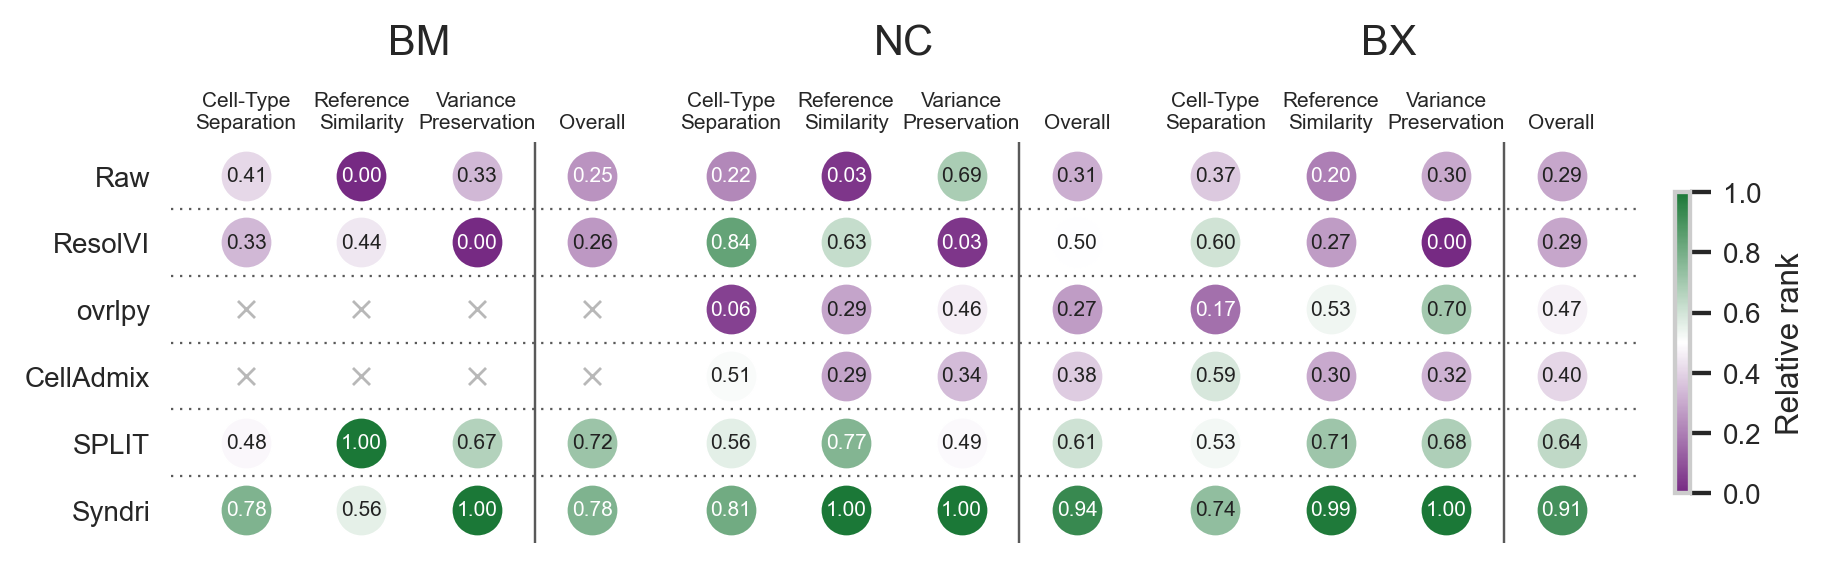

In [40]:
# Dot plot: each score is a colored circle with its value printed inside.
# Missing method/dataset combinations are marked with a gray cross.

fig_dataset, ax_dataset = plt.subplots(
    figsize=(7.5, 2.5), dpi=250
)

from matplotlib.colors import LinearSegmentedColormap

rank_dataset_cmap = LinearSegmentedColormap.from_list(
    'PurpleWhiteGreen',
    ['#762a83', '#ffffff', '#1b7837'],
    N=256
)

rank_norm = plt.Normalize(vmin=0, vmax=1)

overall_mean_by_method = (
    rank_scores_by_dataset
    .groupby('method', observed=True)['Overall']
    .mean()
)

methods_to_sort = [method for method in rank_method_order if method != 'Raw']
methods_to_sort = sorted(
    methods_to_sort,
    key=lambda method: (
        float(overall_mean_by_method.get(method, np.nan))
        if np.isfinite(overall_mean_by_method.get(method, np.nan))
        else -np.inf
    ),
)

rank_methods_for_plot = ['Raw', *methods_to_sort]
rank_dataset_plot_data = rank_dataset_plot_data.reindex(rank_methods_for_plot)

y_positions = np.arange(len(rank_methods_for_plot))

# ------------------------------------------------------------------
# Custom x positions:
#   metric_spacing controls spacing within a dataset group
#   group_gap controls spacing between dataset groups
# ------------------------------------------------------------------
metric_spacing = 1.0
group_gap = 0.20

column_positions = []
x = 0.0

for label in rank_tick_labels:
    column_positions.append(x)

    if label == '':
        # Narrow spacer column between dataset groups
        x += group_gap
    else:
        # Normal spacing between C / R / V / O
        x += metric_spacing

column_positions = np.asarray(column_positions)

# Dataset group centers based on the actual metric positions
rank_group_centers_for_plot = []

for group_index in range(len(rank_dataset_order)):
    start = group_index * 5

    # Four metric columns: C, R, V, O
    metric_indices = [
        start,
        start + 1,
        start + 2,
        start + 3,
    ]

    center = np.mean(column_positions[metric_indices])
    rank_group_centers_for_plot.append(center)

# ------------------------------------------------------------------
# Plot score circles
# ------------------------------------------------------------------
for method_index, method in enumerate(rank_methods_for_plot):
    y = y_positions[method_index]

    values = rank_dataset_plot_data.loc[method].to_numpy(dtype=float)

    for column_index, value in enumerate(values):

        # Blank-label columns are spacing gutters between dataset groups.
        if rank_tick_labels[column_index] == '':
            continue

        x = column_positions[column_index]

        if not np.isfinite(value) or value < 0:
            ax_dataset.scatter(
                x,
                y,
                marker='x',
                s=24,
                color='0.72',
                linewidth=0.8,
                zorder=2,
            )
            continue

        ax_dataset.scatter(
            x,
            y,
            s=220,
            marker='o',
            color=rank_dataset_cmap(rank_norm(value)),
            edgecolor='white',
            linewidth=0.5,
            zorder=3,
        )

        label_color = (
            'white'
            if (value >= 0.75 or value < 0.25)
            else '#222222'
        )

        ax_dataset.text(
            x,
            y,
            f'{value:.2f}',
            transform=ax_dataset.transData,
            ha='center',
            va='center',
            multialignment='center',
            color=label_color,
            fontsize=6,
            zorder=4,
        )

# ------------------------------------------------------------------
# Horizontal dotted rules between method rows
# ------------------------------------------------------------------
for y in np.arange(len(rank_methods_for_plot) - 1) + 0.5:
    ax_dataset.axhline(
        y,
        color='0.35',
        linewidth=0.65,
        linestyle=(0, (1, 3)),
        zorder=1,
    )

# ------------------------------------------------------------------
# Separate V from O within each dataset group
# ------------------------------------------------------------------
for group_index in range(len(rank_dataset_order)):
    start = group_index * 5

    x_v = column_positions[start + 2]
    x_o = column_positions[start + 3]

    x_vo = (x_v + x_o) / 2

    ax_dataset.axvline(
        x_vo,
        color='0.35',
        linewidth=0.7,
        zorder=1,
    )

# ------------------------------------------------------------------
# Axes
# ------------------------------------------------------------------
ax_dataset.set_xlim(
    column_positions.min() - 0.65,
    column_positions.max() + 0.65,
)

ax_dataset.set_ylim(
    len(rank_methods_for_plot) - 0.5,
    -0.5,
)

ax_dataset.set_yticks(
    y_positions,
    rank_methods_for_plot,
)

ax_dataset.set_xticks(
    column_positions,
    rank_tick_labels,
)

ax_dataset.set_xlabel('')
ax_dataset.set_ylabel('')

ax_dataset.grid(
    False,
    axis='both',
    which='both',
)

ax_dataset.minorticks_off()

# ------------------------------------------------------------------
# Dataset labels above each group
# ------------------------------------------------------------------
for center, group_name in zip(
    rank_group_centers_for_plot,
    rank_group_names,
):
    ax_dataset.text(
        center,
        1.2,
        group_name,
        ha='center',
        va='bottom',
        fontsize=12,
        transform=ax_dataset.get_xaxis_transform(),
        clip_on=False,
    )

# ------------------------------------------------------------------
# Tick styling
# ------------------------------------------------------------------
ax_dataset.tick_params(
    axis='x',
    bottom=False,
    labelbottom=False,
    top=True,
    labeltop=True,
    length=0,
    pad=3,
    labelsize=6,
)

ax_dataset.tick_params(
    axis='y',
    rotation=0,
    labelsize=8,
    length=0,
    pad=6,
)

ax_dataset.spines[
    ['top', 'right', 'left', 'bottom']
].set_visible(False)

# ------------------------------------------------------------------
# Optional colorbar
# ------------------------------------------------------------------
rank_scalar = plt.cm.ScalarMappable(
    norm=rank_norm,
    cmap=rank_dataset_cmap,
)
rank_scalar.set_array([])

cbar = fig_dataset.colorbar(
    rank_scalar,
    ax=ax_dataset,
    fraction=0.025,
    pad=0.025,
    shrink=0.75,
    orientation='vertical'
)
cbar.set_label('Relative rank', fontsize=9)
cbar.ax.tick_params(labelsize=8)

# ------------------------------------------------------------------
# Optional abbreviation key
# ------------------------------------------------------------------
# fig_dataset.text(
#     0.20, -0.035,
#     'C: Cell-Type Separation\n'
#     'V: Variance Preservation',
#     ha='left',
#     va='bottom',
#     fontsize=8,
# )

# fig_dataset.text(
#     0.50, -0.035,
#     'R: Reference Similarity\n'
#     'O: Overall',
#     ha='left',
#     va='bottom',
#     fontsize=8,
# )
fig_dataset.tight_layout()
fig_dataset.savefig(
    FIGURE_DIR / 'Figure2_metricheatmap.svg',
    bbox_inches='tight',
)

plt.show()